# Prompt Condition Comparison — TAT German

This notebook compares perplexity scores across four LLM prompt conditions:
**healthy**, **sick**, **neutral**, and **no_prompt**.  
We examine (1) how strongly perplexities correlate across prompt settings,
(2) which prompt yields the best group discrimination (HC vs. patients and per diagnosis),
and (3) whether clinical correlations differ by prompt.

In [32]:
import sys, os, warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu, kruskal
import matplotlib
#matplotlib.use('Agg')

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120

sys.path.insert(0, os.path.abspath('.'))

from services.analysis_service import load_metadata, build_person_df
from functions.analysis.statistics import (
    CLINICAL_VARS,
    group_comparison,
    pairwise_vs_hc,
    clinical_correlations,
    kruskal_wallis_test,
)



In [33]:
def fmt_p(p):
    if p < 0.001:
        return "< 0.001"
    elif p < 0.01:
        return f"{p:.3f}"
    else:
        return f"{p:.2f}"

## 1. Configuration & Data Loading

In [34]:
# ── Prompt conditions ──────────────────────────────────────────
PROMPT_TYPES = ["prompt_healthy", "prompt_sick", "prompt_neutral", "prompt_no_prompt"]
PROMPT_LABELS = {"prompt_healthy": "Healthy", "prompt_sick": "Sick",
                 "prompt_neutral": "Neutral", "prompt_no_prompt": "No prompt"}

BASE_DIR = "/Users/lenze/code/HITKIP/mnm_ppl"
METADATA_CSV = os.path.join(BASE_DIR, "data/00_raw_data/speech_metadata.csv")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "prompt_comparison")
os.makedirs(FIGURE_DIR, exist_ok=True)

MODEL = "qwen"
PPL_VAR = f"{MODEL}_ppl_median"
WC_VAR = f"{MODEL}_total_words"
CONFOUNDER_VARS = ["sex", "age", f"{MODEL}_avg_words", "education", "verbal_IQ"]

clinical_vars_corr = list(dict.fromkeys(CLINICAL_VARS))
clinical_vars_plot = ["GAF", "TLI_Impoverished", "TLI_Disorganization"]

print(f"Prompt conditions: {list(PROMPT_LABELS.values())}")
print(f"Primary metric: {PPL_VAR}")

Prompt conditions: ['Healthy', 'Sick', 'Neutral', 'No prompt']
Primary metric: qwen_ppl_median


In [35]:
# ── Load all four prompt conditions into person-level DataFrames ─
metadata = load_metadata(METADATA_CSV)

dfs = {}  # prompt_type -> person-level DataFrame
for ptype in PROMPT_TYPES:
    suffix = ptype.split('_', 1)[1]
    csv_path = (f"{BASE_DIR}/data/02_perplexities/Qwen2.5-32B-Instruct/"
                f"{ptype}/TAT_german_utterances_with_perplexities_{suffix}.csv")
    sentence_df = pd.read_csv(csv_path)
    person_df = build_person_df(sentence_df, metadata, model_name=MODEL,
                                impute_confounders_cols=CONFOUNDER_VARS)
    dfs[ptype] = person_df
    n_pat = (person_df["is_patient"] == 1).sum()
    n_hc = (person_df["is_patient"] == 0).sum()
    print(f"{PROMPT_LABELS[ptype]:>10}: N={len(person_df)}, HC={n_hc}, Patients={n_pat}, "
          f"PPL median: {person_df[PPL_VAR].median():.2f}")

# Validate clinical vars against actual columns
available_cols = set(dfs[PROMPT_TYPES[0]].columns)
clinical_vars_corr = [v for v in clinical_vars_corr if v in available_cols]
clinical_vars_plot = [v for v in clinical_vars_plot if v in available_cols]
print(f"\nClinical variables available: {len(clinical_vars_corr)}")

                 Variable           HC           BD          MDD          SSD       P
                        n          178           27          119           48        
               Age, years  44.4 ± 13.5  44.6 ± 12.2  44.3 ± 13.8  41.2 ± 12.2    0.47
         Education, years   14.6 ± 3.2   13.4 ± 3.1   13.4 ± 3.0   12.0 ± 2.2 < 0.001
                Verbal IQ 116.1 ± 12.8 111.8 ± 13.2 116.4 ± 14.2 111.9 ± 15.1    0.26
            Female, n (%)  114 (64.0%)   17 (63.0%)   74 (62.2%)   18 (37.5%)   0.009
       Words per sentence  19.1 ± 11.8  20.0 ± 13.5   17.4 ± 9.5   15.3 ± 6.7   0.053
      Number of sentences  72.9 ± 28.3  61.0 ± 23.3  73.3 ± 26.6  74.8 ± 38.1    0.19
        Clinical measures                                                            
            HAMD-17 total            —    5.8 ± 5.8    5.6 ± 5.8    9.2 ± 8.4    0.01
               YMRS total            —    5.8 ± 8.9    0.4 ± 1.0    6.0 ± 7.2 < 0.001
                      GAF            —  59.7 ± 13.3  6

## 2. Cross-Prompt Correlation

How strongly do perplexity scores (per subject) correlate across the four prompt conditions?

In [36]:
# ── Build a wide DataFrame: one column per prompt condition ─────
ppl_wide = pd.DataFrame({"file_id": dfs[PROMPT_TYPES[0]]["file_id"]})
for ptype in PROMPT_TYPES:
    label = PROMPT_LABELS[ptype]
    ppl_wide = ppl_wide.merge(
        dfs[ptype][["file_id", PPL_VAR]].rename(columns={PPL_VAR: label}),
        on="file_id", how="outer"
    )

ppl_cols = list(PROMPT_LABELS.values())
ppl_wide_clean = ppl_wide[ppl_cols].dropna()
print(f"Subjects with all 4 conditions: {len(ppl_wide_clean)}")
print(f"\nDescriptive statistics (median PPL per prompt):")
display(ppl_wide_clean.describe().round(2))

Subjects with all 4 conditions: 371

Descriptive statistics (median PPL per prompt):


,Healthy,Sick,Neutral,No prompt
count,371.00,371.00,371.00,371.00
mean,44.35,48.79,38.99,51.50
std,17.10,18.68,14.70,22.75
min,14.86,15.53,14.70,15.69
25%,32.75,37.09,29.15,37.18
50%,41.47,44.77,36.14,46.15
75%,50.52,55.35,44.13,59.37
max,137.97,140.92,116.76,172.85


Spearman correlation matrix (median PPL across prompt conditions):


,Healthy,Sick,Neutral,No prompt
Healthy,1.000,0.960,0.953,0.918
Sick,0.960,1.000,0.931,0.899
Neutral,0.953,0.931,1.000,0.910
No prompt,0.918,0.899,0.910,1.000


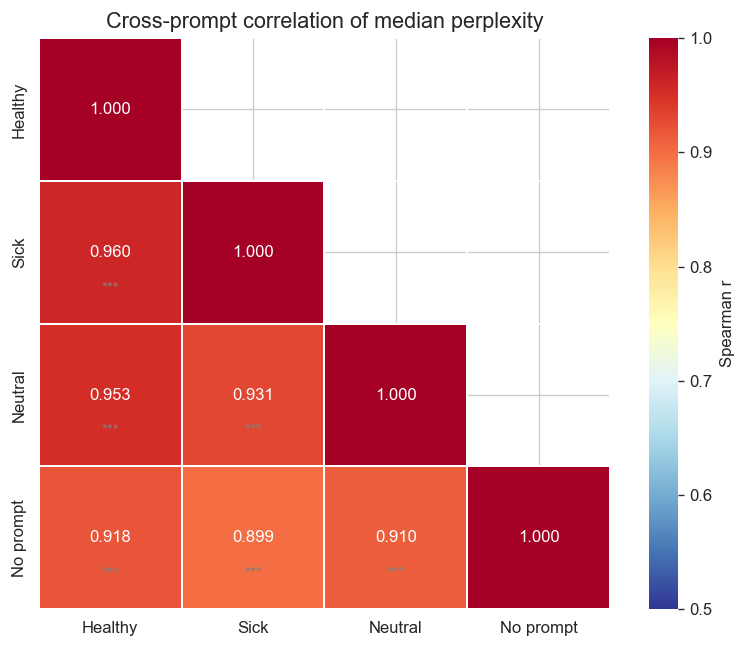

In [37]:
# ── Spearman correlation matrix across prompt conditions ────────
n_prompts = len(ppl_cols)
r_matrix = pd.DataFrame(np.ones((n_prompts, n_prompts)),
                         index=ppl_cols, columns=ppl_cols)
p_matrix = pd.DataFrame(np.zeros((n_prompts, n_prompts)),
                         index=ppl_cols, columns=ppl_cols)

for i, c1 in enumerate(ppl_cols):
    for j, c2 in enumerate(ppl_cols):
        if i < j:
            r, p = spearmanr(ppl_wide_clean[c1], ppl_wide_clean[c2])
            r_matrix.loc[c1, c2] = r
            r_matrix.loc[c2, c1] = r
            p_matrix.loc[c1, c2] = p
            p_matrix.loc[c2, c1] = p

print("Spearman correlation matrix (median PPL across prompt conditions):")
display(r_matrix.round(3))

# Heatmap
fig, ax = plt.subplots(figsize=(7, 5.5))
mask = np.triu(np.ones_like(r_matrix, dtype=bool), k=1)
sns.heatmap(r_matrix.astype(float), annot=True, fmt=".3f", cmap="RdYlBu_r",
            vmin=0.5, vmax=1.0, mask=mask, square=True, linewidths=1,
            cbar_kws={"label": "Spearman r"}, ax=ax)

# Add significance stars
for i in range(n_prompts):
    for j in range(i):
        p = p_matrix.iloc[i, j]
        sig = "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else ""
        if sig:
            ax.text(j + 0.5, i + 0.75, sig, ha="center", va="center", fontsize=9, color="gray")

ax.set_title("Cross-prompt correlation of median perplexity", fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "cross_prompt_correlation.png"), dpi=150, bbox_inches="tight")
plt.show()

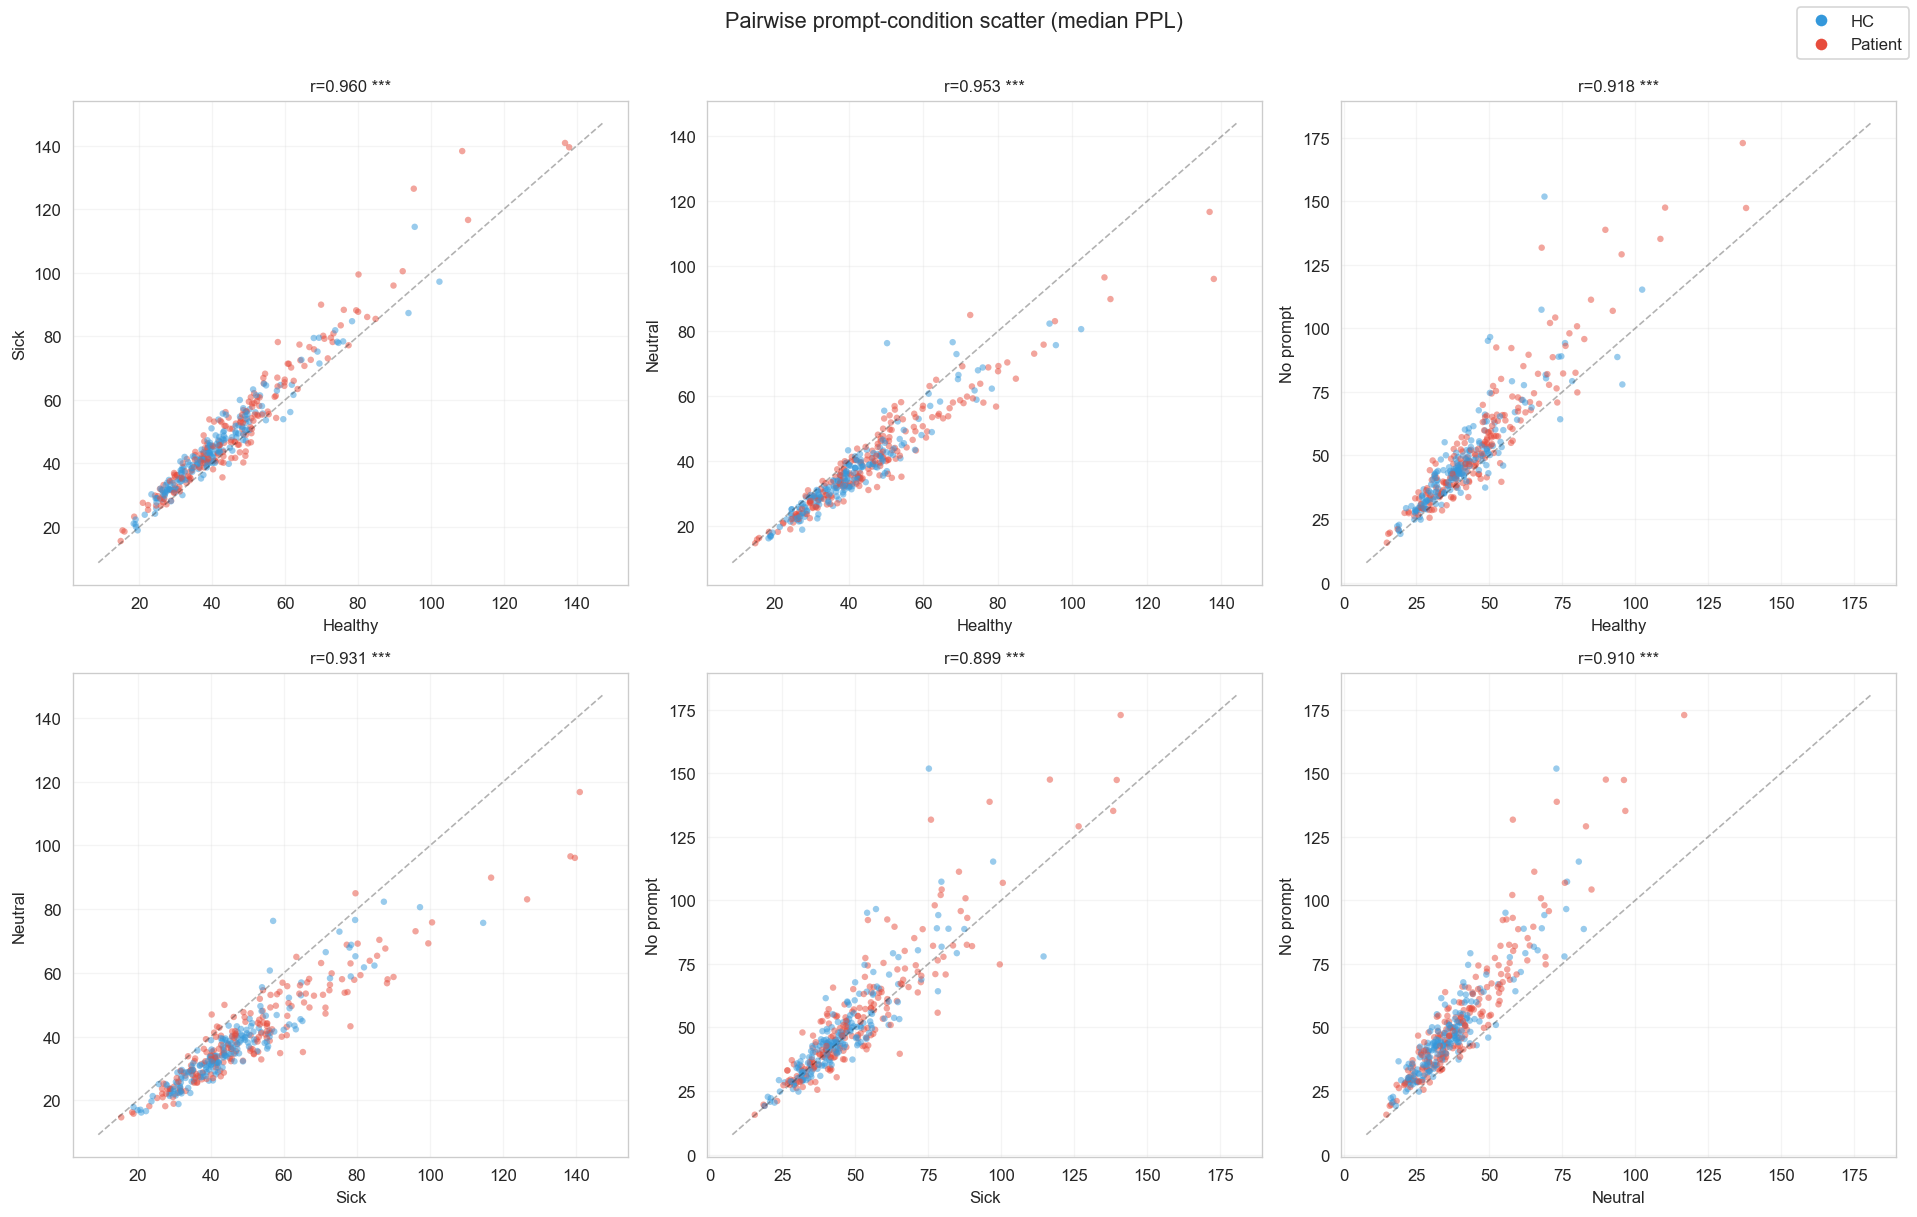

In [38]:
# ── Pairwise scatter plots across prompt conditions ─────────────
from itertools import combinations

pairs = list(combinations(ppl_cols, 2))
n_pairs = len(pairs)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes_flat = axes.flatten()

# Add group info
ppl_wide_grp = ppl_wide.merge(dfs[PROMPT_TYPES[0]][["file_id", "is_patient"]], on="file_id")

for idx, (c1, c2) in enumerate(pairs):
    ax = axes_flat[idx]
    sub = ppl_wide_grp[[c1, c2, "is_patient"]].dropna()
    colors = sub["is_patient"].map({0: "#3498DB", 1: "#E74C3C"})
    ax.scatter(sub[c1], sub[c2], c=colors, alpha=0.5, s=15, edgecolors="none")
    r, p = spearmanr(sub[c1], sub[c2])
    sig = "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"
    ax.set_xlabel(c1); ax.set_ylabel(c2)
    ax.set_title(f"r={r:.3f} {sig}", fontsize=10)
    ax.grid(alpha=0.2)
    # Identity line
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, 'k--', alpha=0.3, lw=1)

# Hide unused axes
for idx in range(n_pairs, len(axes_flat)):
    axes_flat[idx].set_visible(False)

# Legend
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w', markerfacecolor='#3498DB', markersize=8, label='HC'),
                   Line2D([0], [0], marker='o', color='w', markerfacecolor='#E74C3C', markersize=8, label='Patient')]
fig.legend(handles=legend_elements, loc='upper right', fontsize=10)

fig.suptitle("Pairwise prompt-condition scatter (median PPL)", fontsize=13, y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "cross_prompt_scatter.png"), dpi=150, bbox_inches="tight")
plt.show()

## 3. Group Discrimination: HC vs. Patients

Which prompt condition produces the strongest separation between healthy controls and patients?

In [39]:
comp_rows = []
for ptype in PROMPT_TYPES:
    comp = group_comparison(dfs[ptype], PPL_VAR)
    comp["Prompt"] = PROMPT_LABELS[ptype]
    comp_rows.append(comp)

comp_df = pd.DataFrame(comp_rows)
comp_df = comp_df[["Prompt", "Control (M±SD)", "Patient (M±SD)",
                    "Control Median", "Patient Median",
                    "U", "p(MW)", "Cohens d", "r"]]
comp_df = comp_df.sort_values("Cohens d", ascending=False)

# ── NPJ-style rounding ──────
comp_df["p_formatted"] = comp_df["p(MW)"].apply(fmt_p)
comp_df["Cohens d"] = comp_df["Cohens d"].round(2)
comp_df["r"] = comp_df["r"].round(2)
comp_df["Control Median"] = comp_df["Control Median"].round(2)
comp_df["Patient Median"] = comp_df["Patient Median"].round(2)

print("HC vs. Patient — group comparison per prompt condition:")
display(comp_df.style
        .background_gradient(subset=["Cohens d"], cmap="YlOrRd")
        .set_caption("Group comparison: HC vs. Patient by prompt condition"))

comp_df.to_csv(os.path.join(FIGURE_DIR, "group_comparison_hc_vs_patient.csv"), index=False)

HC vs. Patient — group comparison per prompt condition:


,Prompt,Control (M±SD),Patient (M±SD),Control Median,Patient Median,U,p(MW),Cohens d,r,p_formatted
1,Sick,45.38±14.69,51.93±21.28,43.260000,46.640000,20213.000000,0.003267,0.360000,0.180000,0.003
0,Healthy,41.30±14.11,47.07±19.06,39.330000,43.660000,20629.500000,0.001170,0.340000,0.190000,0.001
2,Neutral,36.54±12.76,41.25±15.99,34.110000,38.290000,20389.000000,0.001858,0.320000,0.190000,0.002
3,No prompt,47.84±18.51,54.89±25.64,44.210000,48.720000,19832.000000,0.010104,0.310000,0.150000,0.01


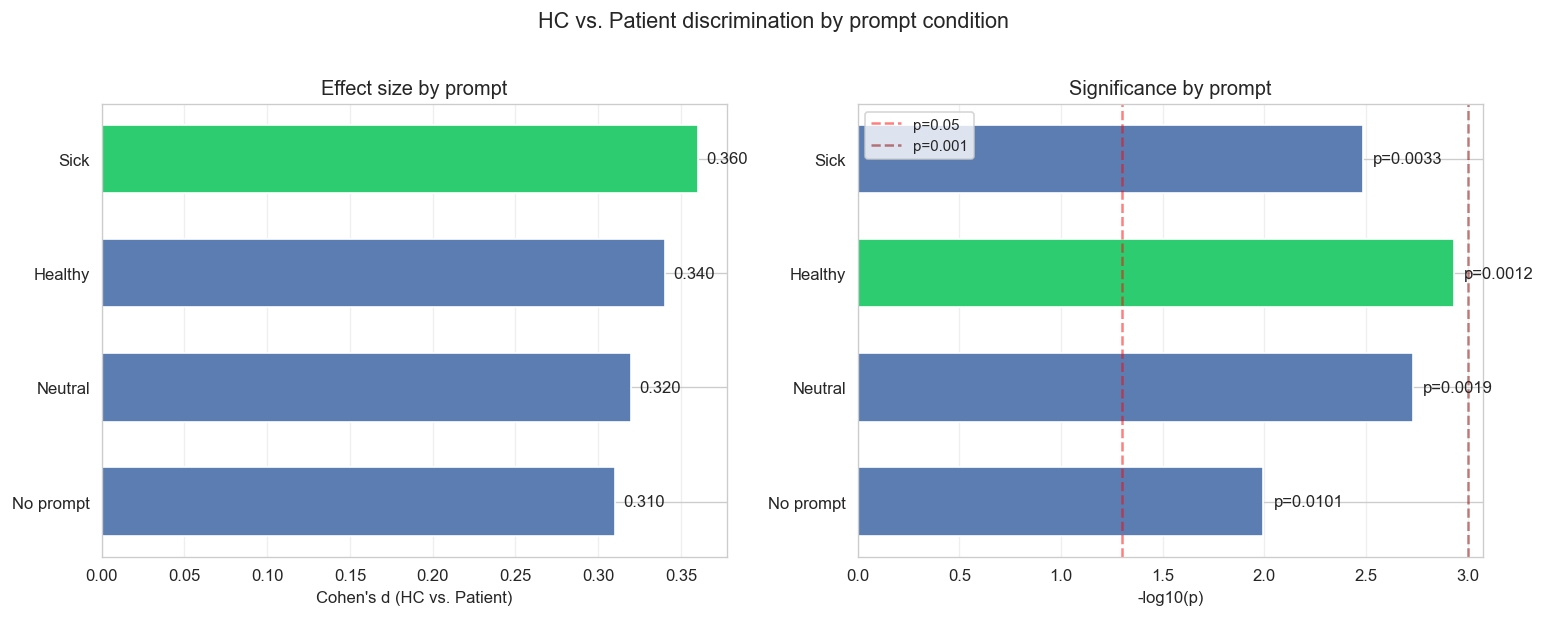

In [40]:
# ── Bar plot: Cohen's d per prompt ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Cohen's d
ax = axes[0]
prompts_sorted = comp_df["Prompt"].tolist()
ds = comp_df["Cohens d"].tolist()
colors = ["#2ECC71" if d == max(ds) else "#5B7DB1" for d in ds]
bars = ax.barh(prompts_sorted, ds, color=colors, edgecolor="white", height=0.6)
ax.set_xlabel("Cohen's d (HC vs. Patient)"); ax.set_title("Effect size by prompt")
ax.invert_yaxis(); ax.grid(axis="x", alpha=0.3)
for bar, d in zip(bars, ds):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f"{d:.3f}", va="center", fontsize=10)

# p-value (MW)
ax = axes[1]
ps = comp_df["p(MW)"].tolist()
log_ps = [-np.log10(p) if p > 0 else 10 for p in ps]
colors_p = ["#2ECC71" if lp == max(log_ps) else "#5B7DB1" for lp in log_ps]
bars = ax.barh(prompts_sorted, log_ps, color=colors_p, edgecolor="white", height=0.6)
ax.axvline(-np.log10(0.05), color="red", ls="--", alpha=0.5, label="p=0.05")
ax.axvline(-np.log10(0.001), color="darkred", ls="--", alpha=0.5, label="p=0.001")
ax.set_xlabel("-log10(p)"); ax.set_title("Significance by prompt")
ax.invert_yaxis(); ax.grid(axis="x", alpha=0.3); ax.legend(fontsize=9)
for bar, p in zip(bars, ps):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
            f"p={p:.4f}", va="center", fontsize=10)

fig.suptitle("HC vs. Patient discrimination by prompt condition", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "group_discrimination_by_prompt.png"), dpi=150, bbox_inches="tight")
plt.show()

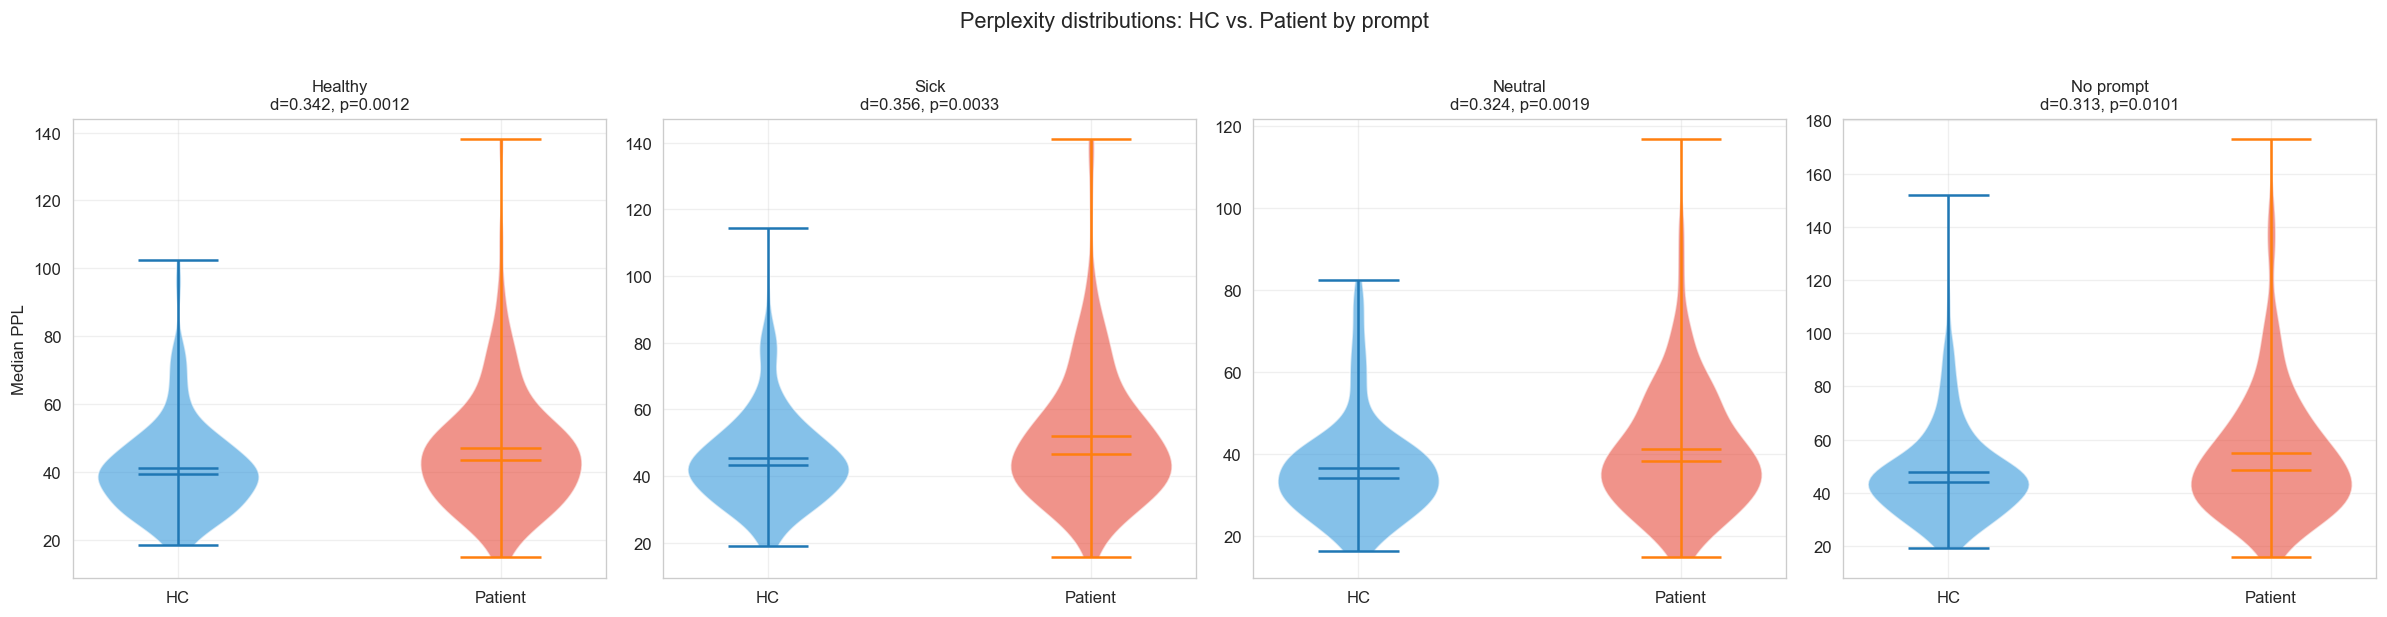

In [41]:
# ── Distribution plots: PPL by group for each prompt ───────────
fig, axes = plt.subplots(1, len(PROMPT_TYPES), figsize=(5 * len(PROMPT_TYPES), 5))

for ax, ptype in zip(axes, PROMPT_TYPES):
    df_p = dfs[ptype]
    hc_vals = df_p[df_p["is_patient"] == 0][PPL_VAR].dropna()
    pat_vals = df_p[df_p["is_patient"] == 1][PPL_VAR].dropna()
    
    parts_hc = ax.violinplot([hc_vals], positions=[0], showmeans=True, showmedians=True)
    parts_pat = ax.violinplot([pat_vals], positions=[1], showmeans=True, showmedians=True)
    for pc in parts_hc["bodies"]:
        pc.set_facecolor("#3498DB"); pc.set_alpha(0.6)
    for pc in parts_pat["bodies"]:
        pc.set_facecolor("#E74C3C"); pc.set_alpha(0.6)
    
    comp = group_comparison(df_p, PPL_VAR)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["HC", "Patient"])
    ax.set_title(f"{PROMPT_LABELS[ptype]}\nd={comp['Cohens d']:.3f}, p={comp['p(MW)']:.4f}",
                 fontsize=10)
    ax.set_ylabel("Median PPL" if ax == axes[0] else "")
    ax.grid(alpha=0.3)

fig.suptitle("Perplexity distributions: HC vs. Patient by prompt", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "distributions_by_prompt.png"), dpi=150, bbox_inches="tight")
plt.show()

## 4. Per-Diagnosis Comparison

Which prompt condition best separates each diagnosis (SSD, MDD, BD) from HC?

In [42]:
# ── Pairwise vs HC per prompt and per diagnosis ────────────────
pw_rows = []
for ptype in PROMPT_TYPES:
    pw = pairwise_vs_hc(dfs[ptype], PPL_VAR)
    for row in pw:
        row["Prompt"] = PROMPT_LABELS[ptype]
        pw_rows.append(row)

pw_df = pd.DataFrame(pw_rows)
pw_df["sig"] = pw_df["p"].apply(
    lambda x: "***" if x < 0.001 else "**" if x < 0.01 else "*" if x < 0.05 else "ns"
)

print("Per-diagnosis vs HC — by prompt condition:")
display(pw_df.pivot_table(index="Diagnosis", columns="Prompt",
                          values="Cohen's d", aggfunc="first")
        .round(3)
        .style.background_gradient(cmap="YlOrRd", axis=1)
        .set_caption("Cohen's d: each diagnosis vs HC, by prompt"))

print("\np-values:")
display(pw_df.pivot_table(index="Diagnosis", columns="Prompt",
                          values="p", aggfunc="first")
        .round(4)
        .style.background_gradient(cmap="YlOrRd_r", axis=1)
        .set_caption("p-values: each diagnosis vs HC, by prompt"))

Per-diagnosis vs HC — by prompt condition:


Prompt,Healthy,Neutral,No prompt,Sick
Diagnosis,,,,
BD,0.274000,0.288000,0.218000,0.324000
MDD,0.157000,0.142000,0.122000,0.172000
SSD,0.884000,0.821000,0.876000,0.909000



p-values:


Prompt,Healthy,Neutral,No prompt,Sick
Diagnosis,,,,
BD,0.156000,0.088800,0.143300,0.216500
MDD,0.057800,0.083200,0.270900,0.091900
SSD,0.000100,0.000200,0.000300,0.000300


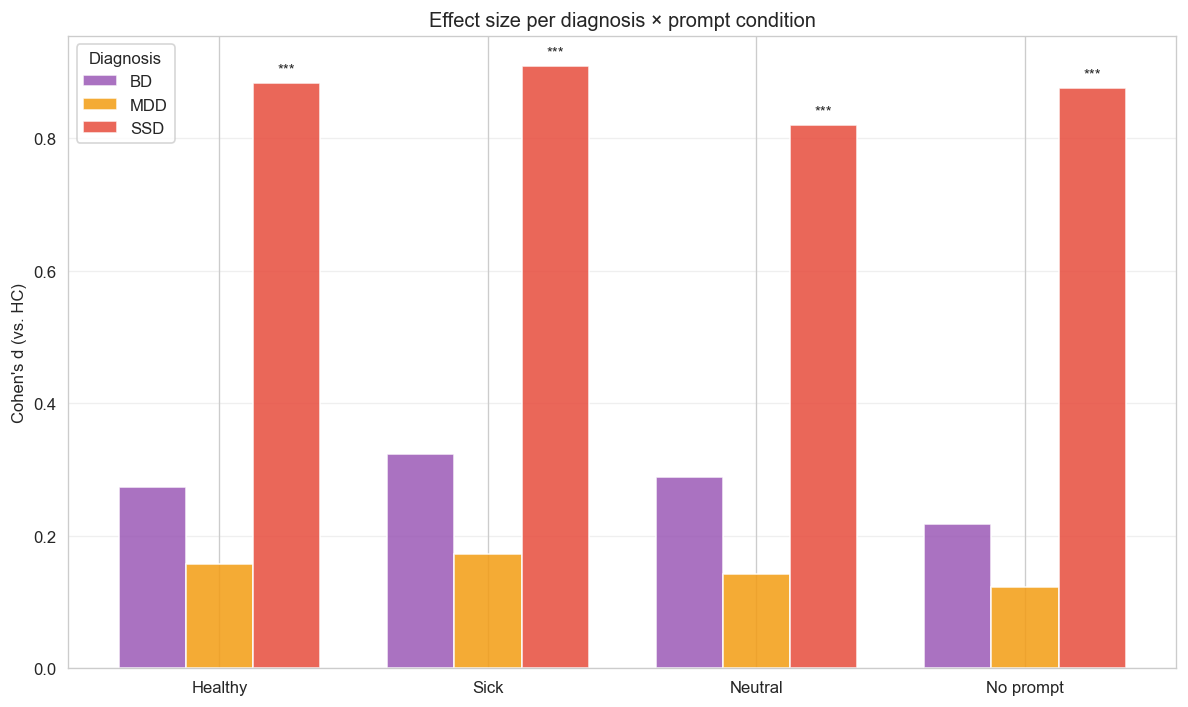

In [43]:
# ── Grouped bar plot: Cohen's d per diagnosis × prompt ──────────
diagnoses = pw_df["Diagnosis"].unique()
prompts = [PROMPT_LABELS[pt] for pt in PROMPT_TYPES]
diag_colors = {"SSD": "#E74C3C", "MDD": "#F39C12", "BD": "#9B59B6"}

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(prompts))
width = 0.25

for i, dx in enumerate(diagnoses):
    dx_data = pw_df[pw_df["Diagnosis"] == dx]
    ds = [dx_data[dx_data["Prompt"] == pr]["Cohen's d"].values[0]
          if pr in dx_data["Prompt"].values else 0 for pr in prompts]
    ps = [dx_data[dx_data["Prompt"] == pr]["p"].values[0]
          if pr in dx_data["Prompt"].values else 1 for pr in prompts]
    bars = ax.bar(x + i * width, ds, width, label=dx,
                  color=diag_colors.get(dx, "#888"), alpha=0.85)
    # Add significance stars
    for bar, p_val in zip(bars, ps):
        sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else ""
        if sig:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    sig, ha="center", va="bottom", fontsize=9)

ax.set_xticks(x + width); ax.set_xticklabels(prompts)
ax.set_ylabel("Cohen's d (vs. HC)"); ax.set_title("Effect size per diagnosis × prompt condition")
ax.legend(title="Diagnosis"); ax.grid(axis="y", alpha=0.3); ax.axhline(0, color="k", lw=0.5)

fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "per_diagnosis_by_prompt.png"), dpi=150, bbox_inches="tight")
plt.show()

In [44]:
# ── Kruskal-Wallis (all diagnoses) per prompt ─────────────────
kw_rows = []
for ptype in PROMPT_TYPES:
    stat, p = kruskal_wallis_test(dfs[ptype], PPL_VAR)
    kw_rows.append({"Prompt": PROMPT_LABELS[ptype], "H": stat, "p": p})

kw_df = pd.DataFrame(kw_rows)
kw_df["sig"] = kw_df["p"].apply(
    lambda x: "***" if x < 0.001 else "**" if x < 0.01 else "*" if x < 0.05 else "ns"
)
print("Kruskal-Wallis (across all diagnostic groups) per prompt:")
display(kw_df.style.format({"H": "{:.3f}", "p": "{:.4f}"}))

Kruskal-Wallis (across all diagnostic groups) per prompt:


,Prompt,H,p,sig
0,Healthy,16.961,0.0007,***
1,Sick,14.649,0.0021,**
2,Neutral,15.990,0.0011,**
3,No prompt,14.578,0.0022,**


## 5. Per-Diagnosis Distribution Across Prompts

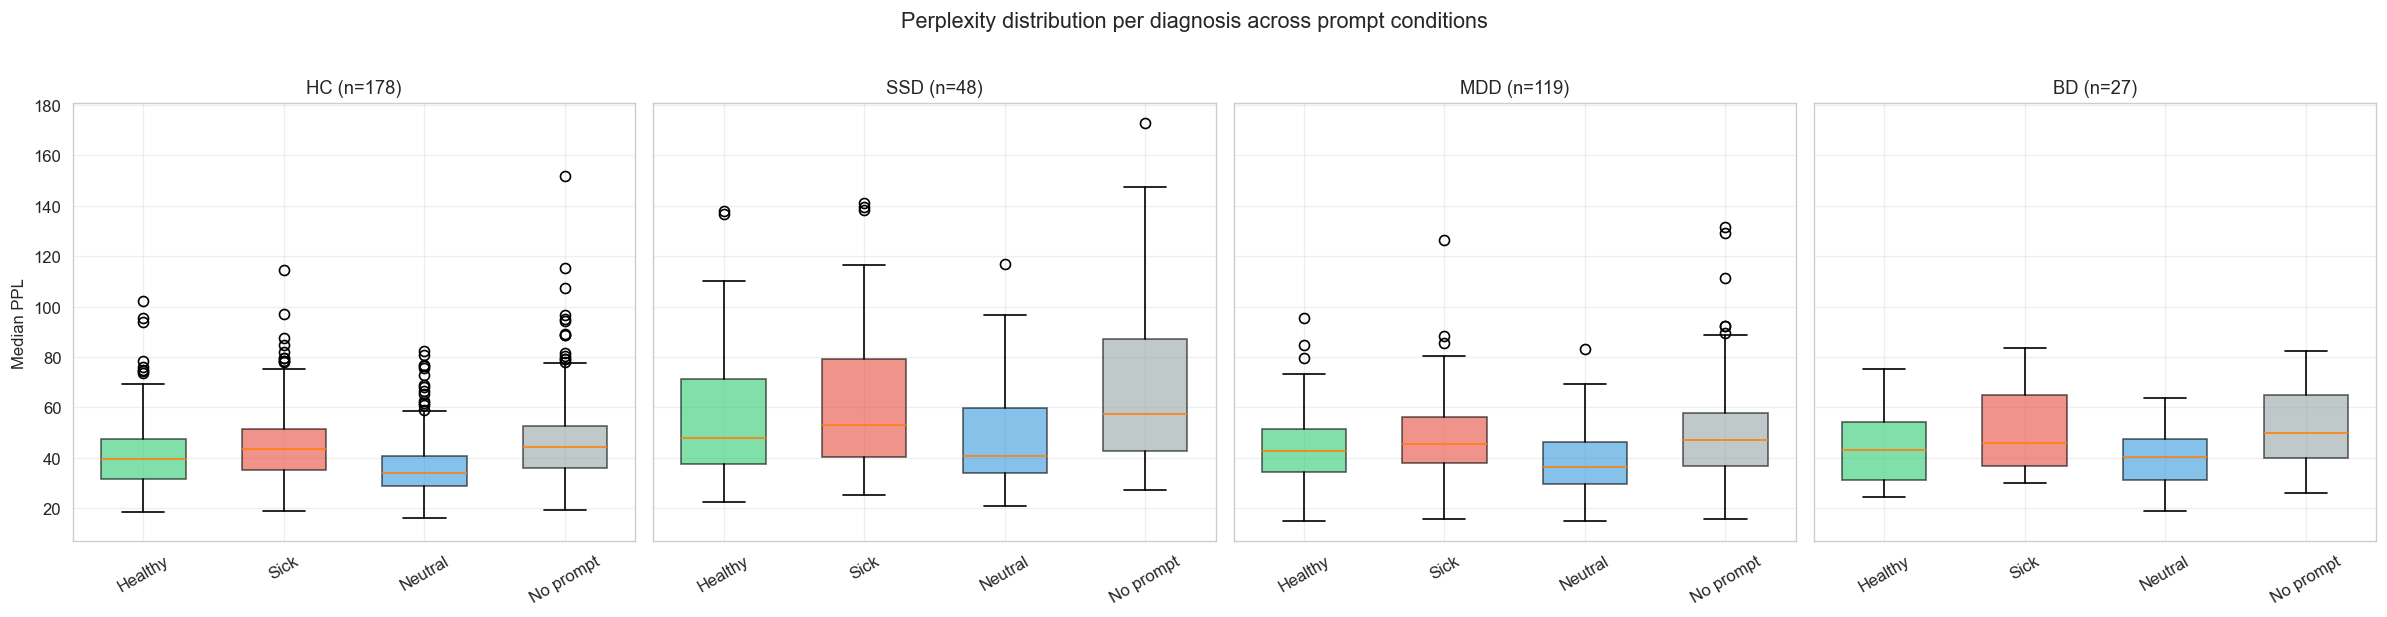

In [45]:
# ── Per-diagnosis boxplot across all prompts ───────────────────
all_diags = ["HC", "SSD", "MDD", "BD"]
fig, axes = plt.subplots(1, len(all_diags), figsize=(5 * len(all_diags), 5), sharey=True)

for ax, dx in zip(axes, all_diags):
    plot_data = []
    for ptype in PROMPT_TYPES:
        vals = dfs[ptype][dfs[ptype]["diagnosis"] == dx][PPL_VAR].dropna()
        plot_data.append(vals)
    
    bp = ax.boxplot(plot_data, labels=[PROMPT_LABELS[pt] for pt in PROMPT_TYPES],
                    patch_artist=True, widths=0.6)
    prompt_colors = ["#2ECC71", "#E74C3C", "#3498DB", "#95A5A6"]
    for patch, color in zip(bp["boxes"], prompt_colors):
        patch.set_facecolor(color); patch.set_alpha(0.6)
    ax.set_title(f"{dx} (n={len(plot_data[0])})", fontsize=11)
    ax.set_ylabel("Median PPL" if ax == axes[0] else "")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.3)

fig.suptitle("Perplexity distribution per diagnosis across prompt conditions", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "per_diagnosis_distributions.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Clinical Correlations by Prompt

Do clinical associations (Spearman r) differ depending on prompt condition?

In [46]:
# ── Clinical correlations per prompt ───────────────────────────
all_corr = {}
for ptype in PROMPT_TYPES:
    patients = dfs[ptype][dfs[ptype]["is_patient"] == 1].copy()
    corr = clinical_correlations(patients, PPL_VAR, clinical_vars_corr)
    corr["Prompt"] = PROMPT_LABELS[ptype]
    all_corr[PROMPT_LABELS[ptype]] = corr

# Combine into a wide table: clinical var × prompt (Spearman r)
corr_combined = pd.concat(all_corr.values(), ignore_index=True)
r_pivot = corr_combined.pivot_table(index="Clinical Variable", columns="Prompt",
                                     values="r", aggfunc="first")
p_pivot = corr_combined.pivot_table(index="Clinical Variable", columns="Prompt",
                                     values="p", aggfunc="first")

# Order columns by prompt
r_pivot = r_pivot[[PROMPT_LABELS[pt] for pt in PROMPT_TYPES]]
p_pivot = p_pivot[[PROMPT_LABELS[pt] for pt in PROMPT_TYPES]]

print("Spearman correlations (patients only): PPL × clinical variables, by prompt")
display(r_pivot.round(3).style.background_gradient(cmap="RdBu_r", axis=1, vmin=-0.4, vmax=0.4)
        .set_caption("Spearman r by prompt condition"))

Spearman correlations (patients only): PPL × clinical variables, by prompt


Prompt,Healthy,Sick,Neutral,No prompt
Clinical Variable,,,,
GAF,-0.213000,-0.201000,-0.208000,-0.224000
HAMD_Sum17,0.128000,0.073000,0.133000,0.159000
LexicalVF,-0.212000,-0.181000,-0.199000,-0.230000
SANS_AbulieApathie_ENIGMA,0.229000,0.213000,0.228000,0.216000
SANS_Affektverflachung_ENIGMA,0.248000,0.247000,0.222000,0.239000
SANS_AlogieParalogie_ENIGMA,0.204000,0.146000,0.204000,0.217000
SANS_Anhedonie_ENIGMA,0.177000,0.145000,0.159000,0.155000
SAPS_BizarresVerhalten_ENIGMA,0.119000,0.094000,0.126000,0.123000
SAPS_Halluzinationen_ENIGMA,0.146000,0.145000,0.151000,0.133000


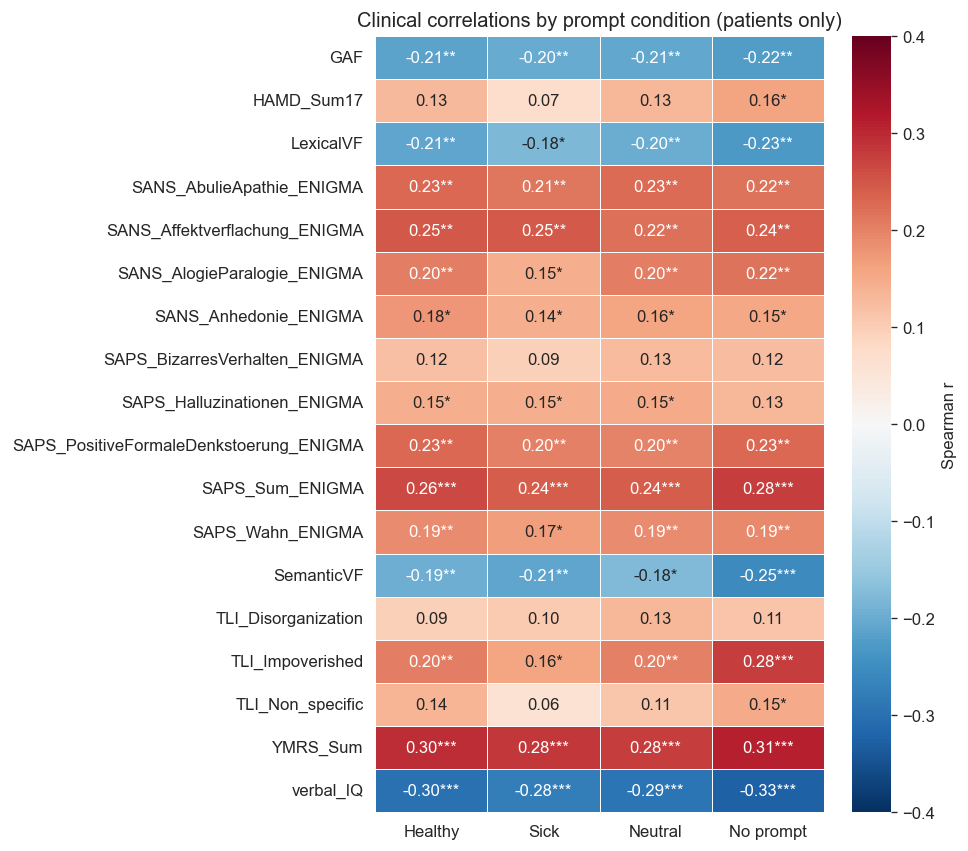

In [47]:
# ── Heatmap: r values for clinical vars × prompts ──────────────
fig, ax = plt.subplots(figsize=(8, max(6, len(r_pivot) * 0.4)))

# Build annotation with significance stars
annot = r_pivot.copy().astype(str)
for cv in r_pivot.index:
    for pr in r_pivot.columns:
        r_val = r_pivot.loc[cv, pr]
        p_val = p_pivot.loc[cv, pr]
        if pd.notna(r_val) and pd.notna(p_val):
            sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else ""
            annot.loc[cv, pr] = f"{r_val:.2f}{sig}"
        else:
            annot.loc[cv, pr] = ""

sns.heatmap(r_pivot.astype(float), annot=annot, fmt="", cmap="RdBu_r",
            center=0, vmin=-0.4, vmax=0.4, linewidths=0.5, ax=ax,
            cbar_kws={"label": "Spearman r"})
ax.set_title("Clinical correlations by prompt condition (patients only)", fontsize=12)
ax.set_ylabel(""); ax.set_xlabel("")
plt.yticks(rotation=0)

fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "clinical_correlations_by_prompt.png"), dpi=150, bbox_inches="tight")
plt.show()

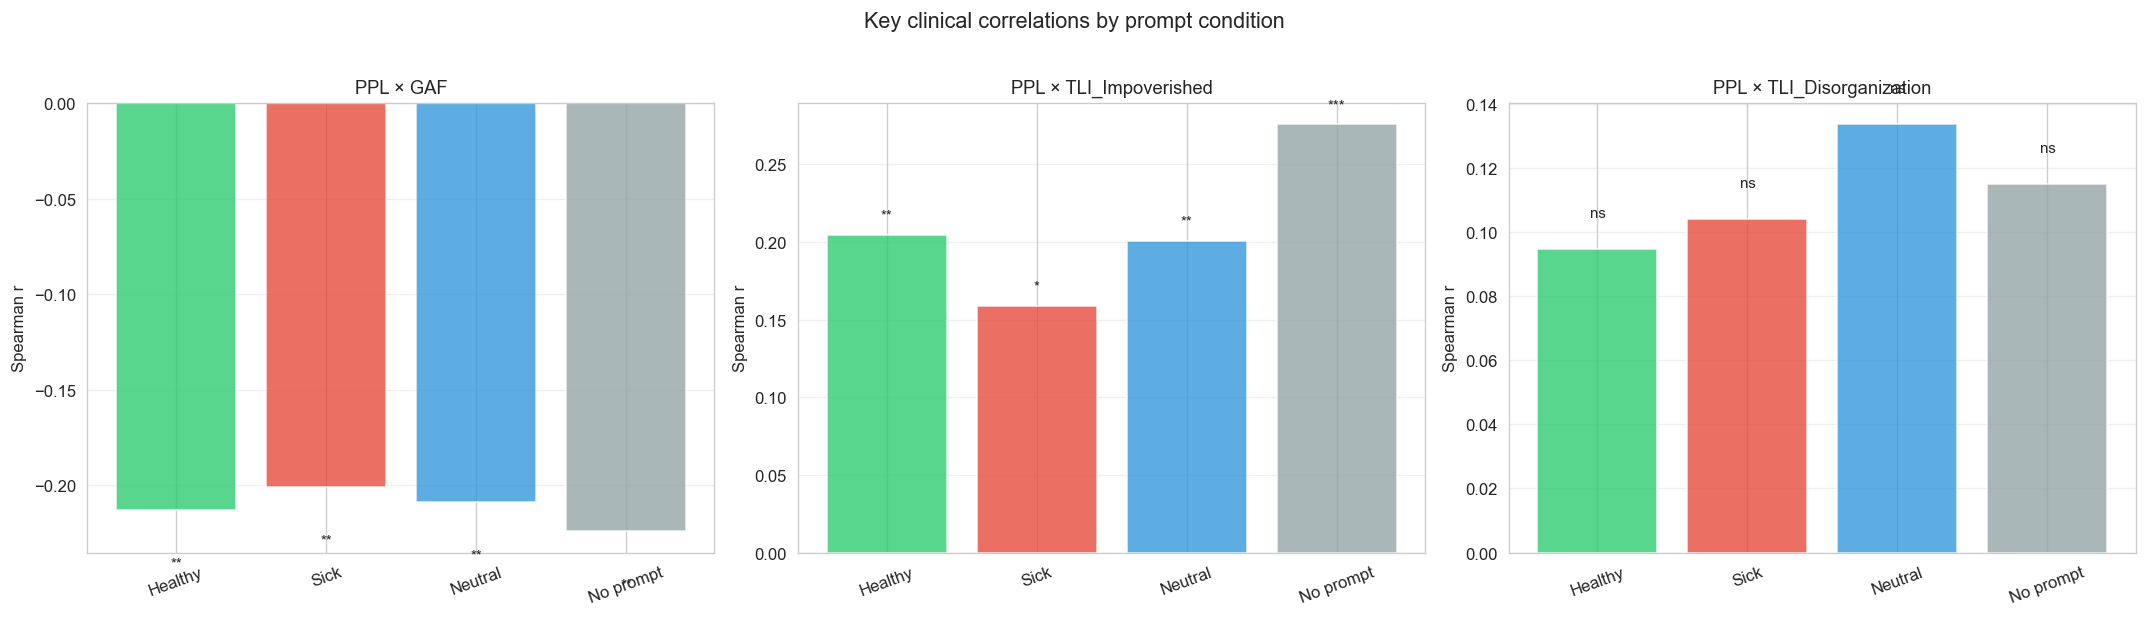

In [48]:
# ── Focused comparison: key clinical variables ─────────────────
fig, axes = plt.subplots(1, len(clinical_vars_plot), figsize=(6 * len(clinical_vars_plot), 5))
if len(clinical_vars_plot) == 1:
    axes = [axes]

for ax, cvar in zip(axes, clinical_vars_plot):
    rs = []
    ps = []
    for ptype in PROMPT_TYPES:
        label = PROMPT_LABELS[ptype]
        r_val = r_pivot.loc[cvar, label] if cvar in r_pivot.index else np.nan
        p_val = p_pivot.loc[cvar, label] if cvar in p_pivot.index else np.nan
        rs.append(r_val)
        ps.append(p_val)
    
    prompt_labels = [PROMPT_LABELS[pt] for pt in PROMPT_TYPES]
    colors = ["#2ECC71", "#E74C3C", "#3498DB", "#95A5A6"]
    bars = ax.bar(prompt_labels, rs, color=colors, alpha=0.8, edgecolor="white")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_ylabel("Spearman r")
    ax.set_title(f"PPL × {cvar}", fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="x", rotation=20)
    
    for bar, r_val, p_val in zip(bars, rs, ps):
        if pd.notna(p_val):
            sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"
            y_pos = bar.get_height() + 0.01 if bar.get_height() >= 0 else bar.get_height() - 0.03
            ax.text(bar.get_x() + bar.get_width()/2, y_pos, sig, ha="center", fontsize=9)

fig.suptitle("Key clinical correlations by prompt condition", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "key_clinical_by_prompt.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Alternative Metrics Comparison Across Prompts

In [49]:
# ── Compare multiple PPL metrics across prompts ────────────────
alt_metrics = [
    f"{MODEL}_ppl_median", f"{MODEL}_ppl_mean",
    f"{MODEL}_ppl_p90", f"{MODEL}_ppl_std",
    f"{MODEL}_ppl_cv", f"{MODEL}_prop_high_ppl",
]
metric_labels = {
    f"{MODEL}_ppl_median": "Median PPL", f"{MODEL}_ppl_mean": "Mean PPL",
    f"{MODEL}_ppl_p90": "P90 PPL", f"{MODEL}_ppl_std": "Std PPL",
    f"{MODEL}_ppl_cv": "CV PPL", f"{MODEL}_prop_high_ppl": "Prop high PPL",
}

alt_rows = []
for ptype in PROMPT_TYPES:
    for metric in alt_metrics:
        if metric not in dfs[ptype].columns:
            continue
        comp = group_comparison(dfs[ptype], metric)
        alt_rows.append({
            "Prompt": PROMPT_LABELS[ptype],
            "Metric": metric_labels.get(metric, metric),
            "Cohens d": comp["Cohens d"],
            "p(MW)": comp["p(MW)"],
        })

alt_df = pd.DataFrame(alt_rows)
alt_pivot = alt_df.pivot_table(index="Metric", columns="Prompt",
                                values="Cohens d", aggfunc="first")
alt_pivot = alt_pivot[[PROMPT_LABELS[pt] for pt in PROMPT_TYPES]]

print("Cohen's d (HC vs Patient) for each metric × prompt:")
display(alt_pivot.round(3).style.background_gradient(cmap="YlOrRd", axis=1)
        .set_caption("Cohen's d by metric × prompt condition"))

Cohen's d (HC vs Patient) for each metric × prompt:


Prompt,Healthy,Sick,Neutral,No prompt
Metric,,,,
CV PPL,-0.101000,-0.120000,-0.038000,0.068000
Mean PPL,-0.011000,-0.109000,-0.008000,-0.105000
Median PPL,0.342000,0.356000,0.324000,0.313000
P90 PPL,-0.073000,-0.104000,-0.098000,-0.072000
Prop high PPL,0.153000,0.141000,0.156000,0.042000
Std PPL,-0.027000,-0.106000,-0.017000,-0.084000


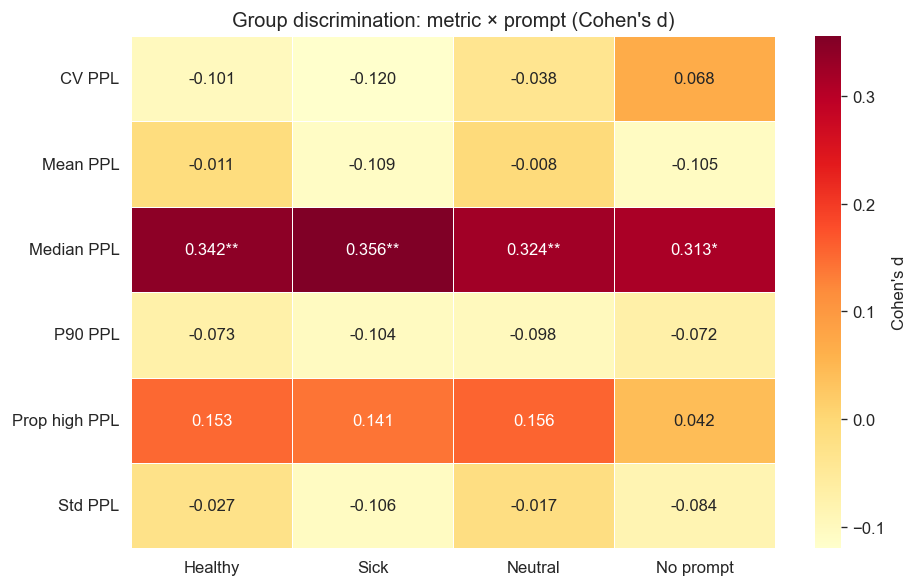

In [50]:
# ── Heatmap: Cohen's d for metrics × prompts ──────────────────
p_alt_pivot = alt_df.pivot_table(index="Metric", columns="Prompt",
                                  values="p(MW)", aggfunc="first")
p_alt_pivot = p_alt_pivot[[PROMPT_LABELS[pt] for pt in PROMPT_TYPES]]

fig, ax = plt.subplots(figsize=(8, 5))

annot = alt_pivot.copy().astype(str)
for m in alt_pivot.index:
    for pr in alt_pivot.columns:
        d = alt_pivot.loc[m, pr]
        p = p_alt_pivot.loc[m, pr]
        if pd.notna(d) and pd.notna(p):
            sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
            annot.loc[m, pr] = f"{d:.3f}{sig}"
        else:
            annot.loc[m, pr] = ""

sns.heatmap(alt_pivot.astype(float), annot=annot, fmt="", cmap="YlOrRd",
            linewidths=0.5, ax=ax, cbar_kws={"label": "Cohen's d"})
ax.set_title("Group discrimination: metric × prompt (Cohen's d)", fontsize=12)
ax.set_ylabel(""); ax.set_xlabel("")
plt.yticks(rotation=0)

fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "metrics_by_prompt_heatmap.png"), dpi=150, bbox_inches="tight")
plt.show()

## 8. Summary: Best Prompt Condition

In [51]:
# ── Summary table ──────────────────────────────────────────────
summary_rows = []
for ptype in PROMPT_TYPES:
    label = PROMPT_LABELS[ptype]
    
    # Global HC vs Patient
    comp = group_comparison(dfs[ptype], PPL_VAR)
    
    # Kruskal-Wallis across all groups
    kw_stat, kw_p = kruskal_wallis_test(dfs[ptype], PPL_VAR)
    
    # Per-diagnosis
    pw = pairwise_vs_hc(dfs[ptype], PPL_VAR)
    pw_d_dict = {r["Diagnosis"]: r["Cohen's d"] for r in pw}
    pw_p_dict = {r["Diagnosis"]: r["p"] for r in pw}
    
    # Key clinical correlations
    patients = dfs[ptype][dfs[ptype]["is_patient"] == 1]
    r_gaf, p_gaf = np.nan, np.nan
    r_tli, p_tli = np.nan, np.nan
    if "GAF" in patients.columns:
        sub = patients[[PPL_VAR, "GAF"]].dropna()
        if len(sub) >= 5:
            r_gaf, p_gaf = spearmanr(sub[PPL_VAR], sub["GAF"])
    if "TLI_Impoverished" in patients.columns:
        sub = patients[[PPL_VAR, "TLI_Impoverished"]].dropna()
        if len(sub) >= 5:
            r_tli, p_tli = spearmanr(sub[PPL_VAR], sub["TLI_Impoverished"])
    
    summary_rows.append({
        "Prompt": label,
        "d (HC vs Pat)": comp["Cohens d"],
        "p (HC vs Pat)": comp["p(MW)"],
        "KW H": kw_stat,
        "KW p": kw_p,
        "d (SSD)": pw_d_dict.get("SSD", np.nan),
        "p (SSD)": pw_p_dict.get("SSD", np.nan),
        "d (MDD)": pw_d_dict.get("MDD", np.nan),
        "p (MDD)": pw_p_dict.get("MDD", np.nan),
        "d (BD)": pw_d_dict.get("BD", np.nan),
        "p (BD)": pw_p_dict.get("BD", np.nan),
        "r (GAF)": r_gaf,
        "r (TLI Imp)": r_tli,
    })

summary = pd.DataFrame(summary_rows)
print("=" * 80)
print("SUMMARY: Prompt condition comparison")
print("=" * 80)
display(summary.style
    .format({"d (HC vs Pat)": "{:.3f}", "p (HC vs Pat)": "{:.4f}",
             "KW H": "{:.2f}", "KW p": "{:.4f}",
             "d (SSD)": "{:.3f}", "p (SSD)": "{:.4f}",
             "d (MDD)": "{:.3f}", "p (MDD)": "{:.4f}",
             "d (BD)": "{:.3f}", "p (BD)": "{:.4f}",
             "r (GAF)": "{:.3f}", "r (TLI Imp)": "{:.3f}"})
    .background_gradient(subset=["d (HC vs Pat)", "d (SSD)", "d (MDD)", "d (BD)"],
                         cmap="YlOrRd")
    .background_gradient(subset=["r (TLI Imp)"], cmap="YlOrRd")
    .set_caption("Overall prompt comparison summary"))

# Identify winner by p-value (lowest p = best discrimination)
best_idx = summary["p (HC vs Pat)"].idxmin()
best_prompt = summary.loc[best_idx, "Prompt"]
best_p = summary.loc[best_idx, "p (HC vs Pat)"]
best_d = summary.loc[best_idx, "d (HC vs Pat)"]
print(f"\nBest global HC vs Patient discrimination: '{best_prompt}' "
      f"(p={best_p:.4f}, d={best_d:.3f})")

for dx in ["SSD", "MDD", "BD"]:
    p_col = f"p ({dx})"
    d_col = f"d ({dx})"
    if p_col in summary.columns:
        best_dx_idx = summary[p_col].idxmin()
        print(f"Best {dx} vs HC: '{summary.loc[best_dx_idx, 'Prompt']}' "
              f"(p={summary.loc[best_dx_idx, p_col]:.4f}, "
              f"d={summary.loc[best_dx_idx, d_col]:.3f})")

SUMMARY: Prompt condition comparison


,Prompt,d (HC vs Pat),p (HC vs Pat),KW H,KW p,d (SSD),p (SSD),d (MDD),p (MDD),d (BD),p (BD),r (GAF),r (TLI Imp)
0,Healthy,0.342,0.0012,16.96,0.0007,0.884,0.0001,0.157,0.0578,0.274,0.1560,-0.213,0.204
1,Sick,0.356,0.0033,14.65,0.0021,0.909,0.0003,0.172,0.0919,0.324,0.2165,-0.201,0.159
2,Neutral,0.324,0.0019,15.99,0.0011,0.821,0.0002,0.142,0.0832,0.288,0.0888,-0.208,0.201
3,No prompt,0.313,0.0101,14.58,0.0022,0.876,0.0003,0.122,0.2709,0.218,0.1433,-0.224,0.276



Best global HC vs Patient discrimination: 'Healthy' (p=0.0012, d=0.342)
Best SSD vs HC: 'Healthy' (p=0.0001, d=0.884)
Best MDD vs HC: 'Healthy' (p=0.0578, d=0.157)
Best BD vs HC: 'Neutral' (p=0.0888, d=0.288)


In [52]:
print(f"\nAll figures saved to: {os.path.abspath(FIGURE_DIR)}")
print("Prompt comparison analysis complete.")


All figures saved to: /Users/lenze/code/HITKIP/mnm_ppl/figures/prompt_comparison
Prompt comparison analysis complete.


## 9. Cross-Model Comparison: Leo Mistral 7B vs Qwen 32B (no_prompt)

How much do per-subject perplexity scores overlap between the two models
under the **no_prompt** condition?  We compare subject-level medians,
correlations, group-discrimination, and clinical associations.

In [53]:
# ── Load Leo Mistral no_prompt data ────────────────────────────
LEO_MODEL = "leo"
LEO_CSV = (f"{BASE_DIR}/data/02_perplexities/leo-mistral-hessianai-7b-chat-instruct/"
           f"prompt_no_prompt/TAT_german_utterances_with_perplexities_no_prompt.csv")

leo_sentence_df = pd.read_csv(LEO_CSV)
LEO_CONFOUNDER_VARS = ["sex", "age", f"{LEO_MODEL}_avg_words", "education", "verbal_IQ"]
leo_person_df = build_person_df(leo_sentence_df, metadata, model_name=LEO_MODEL,
                                impute_confounders_cols=LEO_CONFOUNDER_VARS)

LEO_PPL = f"{LEO_MODEL}_ppl_median"
QWEN_PPL = PPL_VAR  # qwen_ppl_median

# Qwen no_prompt already loaded
qwen_person_df = dfs["prompt_no_prompt"]

print(f"Leo Mistral 7B : N={len(leo_person_df)}, "
      f"PPL median: {leo_person_df[LEO_PPL].median():.2f}")
print(f"Qwen 32B       : N={len(qwen_person_df)}, "
      f"PPL median: {qwen_person_df[QWEN_PPL].median():.2f}")

                 Variable           HC           BD          MDD          SSD       P
                        n          178           27          119           48        
               Age, years  44.4 ± 13.5  44.6 ± 12.2  44.3 ± 13.8  41.2 ± 12.2    0.47
         Education, years   14.6 ± 3.2   13.4 ± 3.1   13.4 ± 3.0   12.0 ± 2.2 < 0.001
                Verbal IQ 116.1 ± 12.8 111.8 ± 13.2 116.4 ± 14.2 111.9 ± 15.1    0.26
            Female, n (%)  114 (64.0%)   17 (63.0%)   74 (62.2%)   18 (37.5%)   0.009
       Words per sentence  20.3 ± 11.1  19.5 ± 13.0   18.9 ± 9.8   15.6 ± 6.4   0.005
      Number of sentences  66.4 ± 26.7  61.9 ± 22.9  66.1 ± 24.9  71.4 ± 36.8    0.90
        Clinical measures                                                            
            HAMD-17 total            —    5.8 ± 5.8    5.6 ± 5.8    9.2 ± 8.4    0.01
               YMRS total            —    5.8 ± 8.9    0.4 ± 1.0    6.0 ± 7.2 < 0.001
                      GAF            —  59.7 ± 13.3  6

In [54]:
# ── Merge both models on file_id ───────────────────────────────
cross_model = leo_person_df[["file_id", LEO_PPL, "is_patient", "diagnosis"]].merge(
    qwen_person_df[["file_id", QWEN_PPL]], on="file_id", how="inner"
)
print(f"Subjects in both models: {len(cross_model)}")
print(f"  HC      : {(cross_model['is_patient'] == 0).sum()}")
print(f"  Patient : {(cross_model['is_patient'] == 1).sum()}")

# ── Spearman correlation ───────────────────────────────────────
r_all, p_all = spearmanr(cross_model[LEO_PPL], cross_model[QWEN_PPL])
print(f"\nOverall Spearman r = {r_all:.3f}, p = {fmt_p(p_all)}")

# Per group
for grp, label in [(0, "HC"), (1, "Patient")]:
    sub = cross_model[cross_model["is_patient"] == grp]
    r, p = spearmanr(sub[LEO_PPL], sub[QWEN_PPL])
    print(f"  {label:>8}: r = {r:.3f}, p = {fmt_p(p)} (n={len(sub)})")

# Per diagnosis
for dx in cross_model["diagnosis"].dropna().unique():
    sub = cross_model[cross_model["diagnosis"] == dx]
    if len(sub) >= 5:
        r, p = spearmanr(sub[LEO_PPL], sub[QWEN_PPL])
        print(f"  {dx:>8}: r = {r:.3f}, p = {fmt_p(p)} (n={len(sub)})")

Subjects in both models: 371
  HC      : 178
  Patient : 193

Overall Spearman r = 0.814, p = < 0.001
        HC: r = 0.812, p = < 0.001 (n=178)
   Patient: r = 0.812, p = < 0.001 (n=193)
       MDD: r = 0.771, p = < 0.001 (n=119)
        HC: r = 0.812, p = < 0.001 (n=178)
       SSD: r = 0.878, p = < 0.001 (n=48)
        BD: r = 0.765, p = < 0.001 (n=26)


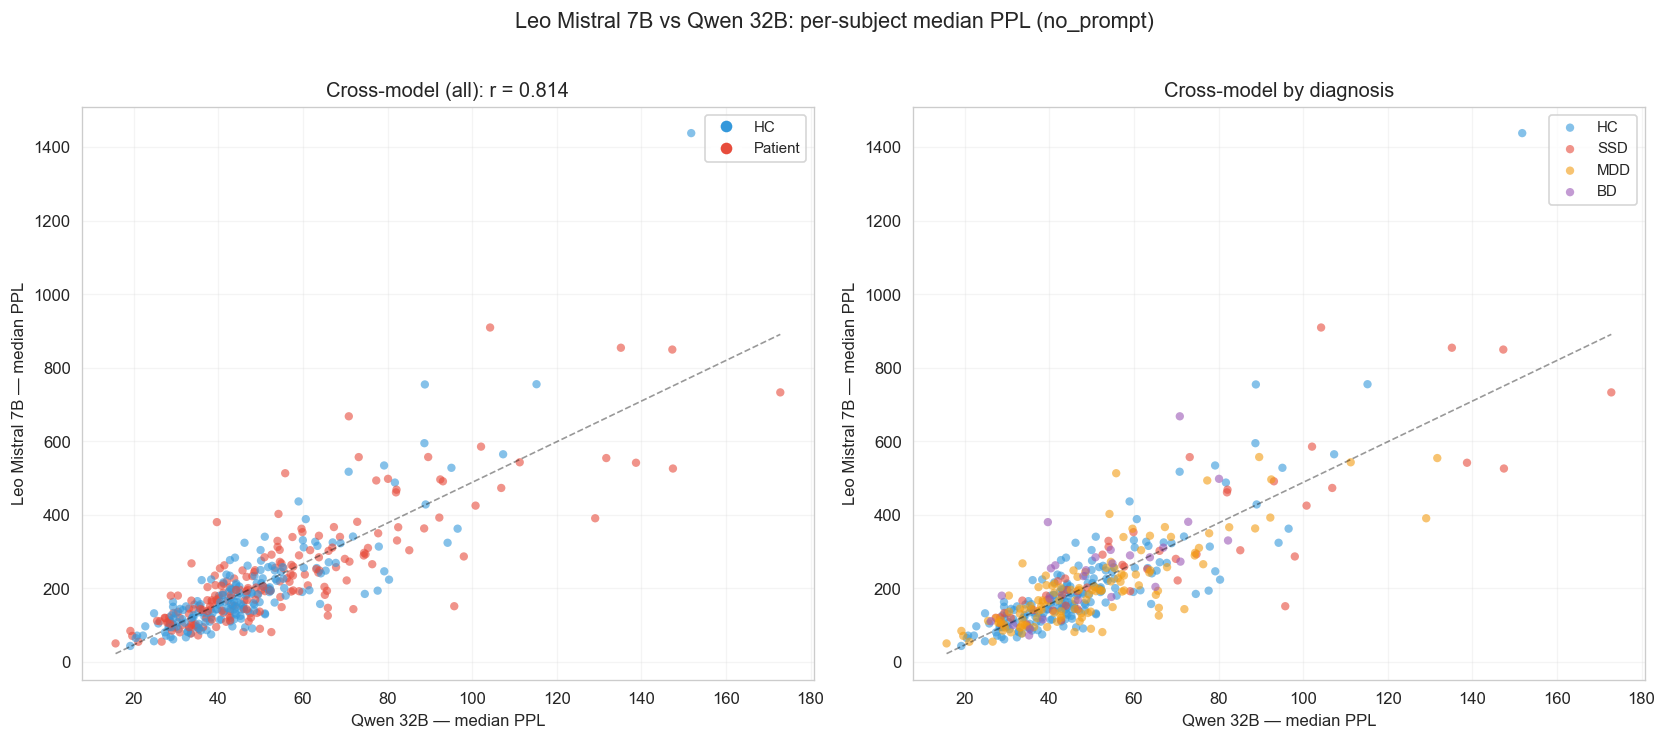

In [55]:
# ── Scatter plot: Leo Mistral vs Qwen (per subject) ────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Panel A: colored by HC vs Patient
ax = axes[0]
colors = cross_model["is_patient"].map({0: "#3498DB", 1: "#E74C3C"})
ax.scatter(cross_model[QWEN_PPL], cross_model[LEO_PPL],
           c=colors, alpha=0.6, s=25, edgecolors="none")
# Identity-ish reference: fit line
from numpy.polynomial.polynomial import polyfit
b, m = polyfit(cross_model[QWEN_PPL], cross_model[LEO_PPL], 1)
x_range = np.linspace(cross_model[QWEN_PPL].min(), cross_model[QWEN_PPL].max(), 100)
ax.plot(x_range, b + m * x_range, 'k--', alpha=0.4, lw=1, label=f"fit (slope={m:.2f})")
ax.set_xlabel("Qwen 32B — median PPL")
ax.set_ylabel("Leo Mistral 7B — median PPL")
ax.set_title(f"Cross-model (all): r = {r_all:.3f}")
ax.legend(fontsize=9)
ax.grid(alpha=0.2)

from matplotlib.lines import Line2D
legend_el = [Line2D([0], [0], marker='o', color='w', markerfacecolor='#3498DB', markersize=8, label='HC'),
             Line2D([0], [0], marker='o', color='w', markerfacecolor='#E74C3C', markersize=8, label='Patient')]
ax.legend(handles=legend_el, fontsize=9)

# Panel B: colored by diagnosis
ax = axes[1]
diag_colors = {"HC": "#3498DB", "SSD": "#E74C3C", "MDD": "#F39C12", "BD": "#9B59B6"}
for dx, color in diag_colors.items():
    sub = cross_model[cross_model["diagnosis"] == dx]
    ax.scatter(sub[QWEN_PPL], sub[LEO_PPL], c=color, alpha=0.6, s=25,
               edgecolors="none", label=dx)
ax.plot(x_range, b + m * x_range, 'k--', alpha=0.4, lw=1)
ax.set_xlabel("Qwen 32B — median PPL")
ax.set_ylabel("Leo Mistral 7B — median PPL")
ax.set_title("Cross-model by diagnosis")
ax.legend(fontsize=9); ax.grid(alpha=0.2)

fig.suptitle("Leo Mistral 7B vs Qwen 32B: per-subject median PPL (no_prompt)", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "cross_model_leo_vs_qwen_scatter.png"), dpi=150, bbox_inches="tight")
plt.show()

In [56]:
# ── Group discrimination comparison ────────────────────────────
comp_leo = group_comparison(leo_person_df, LEO_PPL)
comp_qwen = group_comparison(qwen_person_df, QWEN_PPL)

model_comp = pd.DataFrame([
    {"Model": "Leo Mistral 7B", "Control (M±SD)": comp_leo["Control (M±SD)"],
     "Patient (M±SD)": comp_leo["Patient (M±SD)"],
     "Control Median": round(comp_leo["Control Median"], 2),
     "Patient Median": round(comp_leo["Patient Median"], 2),
     "U": comp_leo["U"], "p(MW)": fmt_p(comp_leo["p(MW)"]),
     "Cohen's d": round(comp_leo["Cohens d"], 3),
     "r": round(comp_leo["r"], 3)},
    {"Model": "Qwen 32B", "Control (M±SD)": comp_qwen["Control (M±SD)"],
     "Patient (M±SD)": comp_qwen["Patient (M±SD)"],
     "Control Median": round(comp_qwen["Control Median"], 2),
     "Patient Median": round(comp_qwen["Patient Median"], 2),
     "U": comp_qwen["U"], "p(MW)": fmt_p(comp_qwen["p(MW)"]),
     "Cohen's d": round(comp_qwen["Cohens d"], 3),
     "r": round(comp_qwen["r"], 3)},
])

print("HC vs. Patient — model comparison (no_prompt condition):")
display(model_comp.style
        .background_gradient(subset=["Cohen's d"], cmap="YlOrRd")
        .set_caption("Group discrimination: Leo Mistral 7B vs Qwen 32B"))

HC vs. Patient — model comparison (no_prompt condition):


,Model,Control (M±SD),Patient (M±SD),Control Median,Patient Median,U,p(MW),Cohen's d,r
0,Leo Mistral 7B,202.59±149.10,236.64±150.98,163.860000,195.780000,20020.000000,0.008,0.227000,0.160000
1,Qwen 32B,47.84±18.51,54.89±25.64,44.210000,48.720000,19832.000000,0.01,0.313000,0.155000


In [57]:
# ── Per-diagnosis comparison: Leo vs Qwen ──────────────────────
pw_leo = pairwise_vs_hc(leo_person_df, LEO_PPL)
pw_qwen = pairwise_vs_hc(qwen_person_df, QWEN_PPL)

pw_combined = []
for row in pw_leo:
    row["Model"] = "Leo Mistral 7B"
    pw_combined.append(row)
for row in pw_qwen:
    row["Model"] = "Qwen 32B"
    pw_combined.append(row)

pw_comb_df = pd.DataFrame(pw_combined)

print("Per-diagnosis vs HC — Leo Mistral 7B vs Qwen 32B (no_prompt):")
d_pivot = pw_comb_df.pivot_table(index="Diagnosis", columns="Model",
                                  values="Cohen's d", aggfunc="first")
p_pivot_dx = pw_comb_df.pivot_table(index="Diagnosis", columns="Model",
                                     values="p", aggfunc="first")

display(d_pivot.round(3).style
        .background_gradient(cmap="YlOrRd", axis=1)
        .set_caption("Cohen's d: each diagnosis vs HC, by model"))

print("\np-values:")
display(p_pivot_dx.round(4).style
        .background_gradient(cmap="YlOrRd_r", axis=1)
        .set_caption("p-values: each diagnosis vs HC, by model"))

Per-diagnosis vs HC — Leo Mistral 7B vs Qwen 32B (no_prompt):


Model,Leo Mistral 7B,Qwen 32B
Diagnosis,,
BD,0.329000,0.218000
MDD,-0.005000,0.122000
SSD,0.686000,0.876000



p-values:


Model,Leo Mistral 7B,Qwen 32B
Diagnosis,,
BD,0.013200,0.143300
MDD,0.565800,0.270900
SSD,0.000100,0.000300


In [58]:
# ── Clinical correlations: Leo vs Qwen ─────────────────────────
patients_leo = leo_person_df[leo_person_df["is_patient"] == 1].copy()
patients_qwen = qwen_person_df[qwen_person_df["is_patient"] == 1].copy()

corr_leo = clinical_correlations(patients_leo, LEO_PPL, clinical_vars_corr)
corr_qwen = clinical_correlations(patients_qwen, QWEN_PPL, clinical_vars_corr)
corr_leo["Model"] = "Leo Mistral 7B"
corr_qwen["Model"] = "Qwen 32B"

corr_both = pd.concat([corr_leo, corr_qwen], ignore_index=True)

r_model_pivot = corr_both.pivot_table(index="Clinical Variable", columns="Model",
                                       values="r", aggfunc="first")
p_model_pivot = corr_both.pivot_table(index="Clinical Variable", columns="Model",
                                       values="p", aggfunc="first")

print("Clinical correlations (patients, no_prompt): Leo Mistral 7B vs Qwen 32B")
display(r_model_pivot.round(3).style
        .background_gradient(cmap="RdBu_r", axis=1, vmin=-0.4, vmax=0.4)
        .set_caption("Spearman r by model"))

Clinical correlations (patients, no_prompt): Leo Mistral 7B vs Qwen 32B


Model,Leo Mistral 7B,Qwen 32B
Clinical Variable,,
GAF,-0.248000,-0.224000
HAMD_Sum17,0.127000,0.159000
LexicalVF,-0.275000,-0.230000
SANS_AbulieApathie_ENIGMA,0.240000,0.216000
SANS_Affektverflachung_ENIGMA,0.225000,0.239000
SANS_AlogieParalogie_ENIGMA,0.183000,0.217000
SANS_Anhedonie_ENIGMA,0.196000,0.155000
SAPS_BizarresVerhalten_ENIGMA,0.103000,0.123000
SAPS_Halluzinationen_ENIGMA,0.133000,0.133000


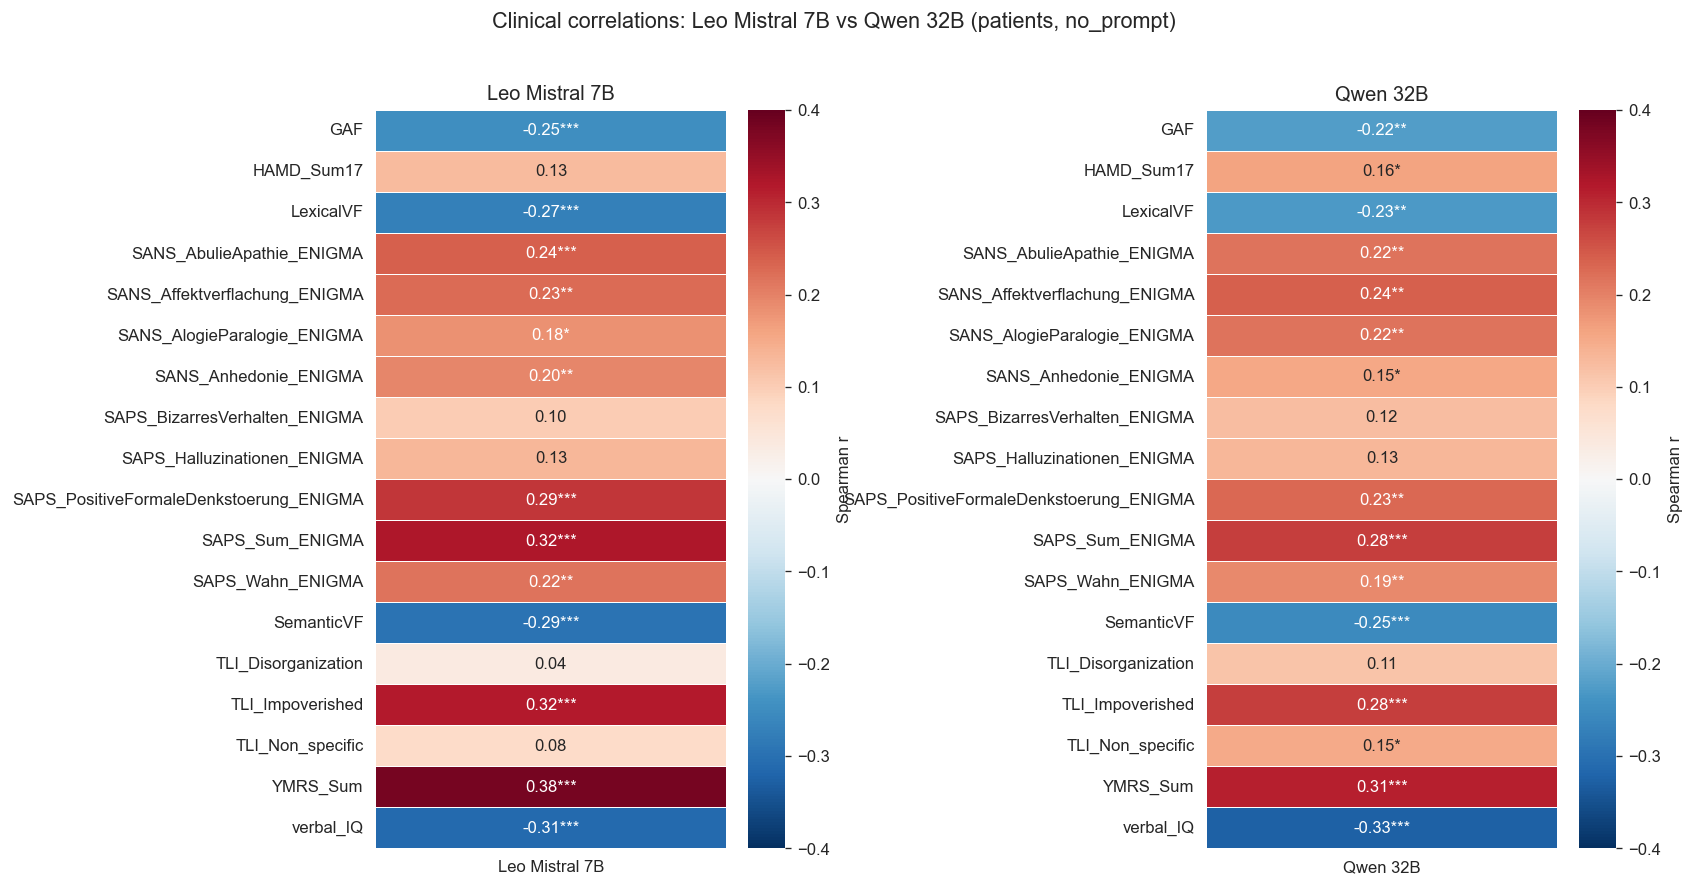

In [59]:
# ── Heatmap: clinical correlation comparison (Leo vs Qwen) ─────
fig, axes = plt.subplots(1, 2, figsize=(14, max(6, len(r_model_pivot) * 0.4)))

for ax, model_col in zip(axes, ["Leo Mistral 7B", "Qwen 32B"]):
    r_vals = r_model_pivot[model_col].astype(float)
    p_vals = p_model_pivot[model_col]
    
    annot_vals = []
    for cv in r_vals.index:
        r_v = r_vals[cv]
        p_v = p_vals[cv]
        if pd.notna(r_v) and pd.notna(p_v):
            sig = "***" if p_v < 0.001 else "**" if p_v < 0.01 else "*" if p_v < 0.05 else ""
            annot_vals.append(f"{r_v:.2f}{sig}")
        else:
            annot_vals.append("")
    
    r_frame = pd.DataFrame(r_vals.values.reshape(-1, 1),
                           index=r_vals.index, columns=[model_col])
    annot_frame = pd.DataFrame(annot_vals, index=r_vals.index, columns=[model_col])
    
    sns.heatmap(r_frame, annot=annot_frame, fmt="", cmap="RdBu_r",
                center=0, vmin=-0.4, vmax=0.4, linewidths=0.5, ax=ax,
                cbar_kws={"label": "Spearman r"})
    ax.set_title(model_col, fontsize=12)
    ax.set_ylabel("")
    plt.sca(ax)
    plt.yticks(rotation=0)

fig.suptitle("Clinical correlations: Leo Mistral 7B vs Qwen 32B (patients, no_prompt)",
             fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "cross_model_clinical_correlations.png"),
            dpi=150, bbox_inches="tight")
plt.show()

Rank-based overlap (n=371):
  Top 25% PPL — Jaccard = 0.576 (68/118 subjects overlap)
  Bottom 25% PPL — Jaccard = 0.563 (67/119 subjects overlap)


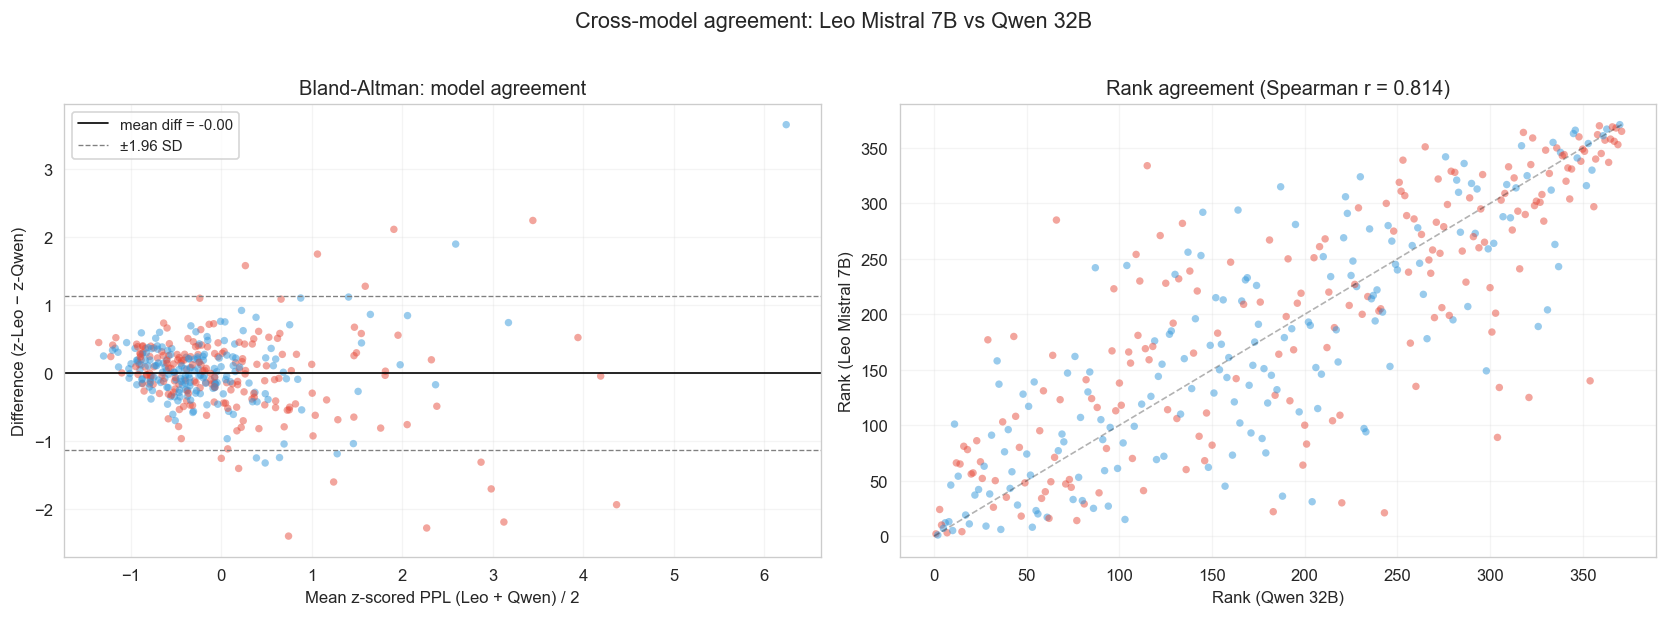

In [60]:
# ── Bland-Altman–style agreement + rank overlap ────────────────
from scipy.stats import rankdata

# Rank-based agreement: are the same subjects "high PPL" in both models?
merged = cross_model[[LEO_PPL, QWEN_PPL, "is_patient", "diagnosis"]].dropna()
merged["rank_leo"] = rankdata(merged[LEO_PPL])
merged["rank_qwen"] = rankdata(merged[QWEN_PPL])

# Top-25% overlap
n = len(merged)
q75_leo = np.percentile(merged["rank_leo"], 75)
q75_qwen = np.percentile(merged["rank_qwen"], 75)
top_leo = set(merged[merged["rank_leo"] >= q75_leo].index)
top_qwen = set(merged[merged["rank_qwen"] >= q75_qwen].index)
overlap_top = len(top_leo & top_qwen)
union_top = len(top_leo | top_qwen)
jaccard_top = overlap_top / union_top if union_top > 0 else 0

# Bottom-25% overlap
q25_leo = np.percentile(merged["rank_leo"], 25)
q25_qwen = np.percentile(merged["rank_qwen"], 25)
bot_leo = set(merged[merged["rank_leo"] <= q25_leo].index)
bot_qwen = set(merged[merged["rank_qwen"] <= q25_qwen].index)
overlap_bot = len(bot_leo & bot_qwen)
union_bot = len(bot_leo | bot_qwen)
jaccard_bot = overlap_bot / union_bot if union_bot > 0 else 0

print(f"Rank-based overlap (n={n}):")
print(f"  Top 25% PPL — Jaccard = {jaccard_top:.3f} "
      f"({overlap_top}/{union_top} subjects overlap)")
print(f"  Bottom 25% PPL — Jaccard = {jaccard_bot:.3f} "
      f"({overlap_bot}/{union_bot} subjects overlap)")

# Bland-Altman style: difference vs mean (on z-scored PPL for comparability)
from scipy.stats import zscore
z_leo = zscore(merged[LEO_PPL])
z_qwen = zscore(merged[QWEN_PPL])
diff = z_leo - z_qwen
mean_z = (z_leo + z_qwen) / 2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bland-Altman
ax = axes[0]
colors = merged["is_patient"].map({0: "#3498DB", 1: "#E74C3C"})
ax.scatter(mean_z, diff, c=colors, alpha=0.5, s=20, edgecolors="none")
ax.axhline(diff.mean(), color="k", ls="-", lw=1, label=f"mean diff = {diff.mean():.2f}")
ax.axhline(diff.mean() + 1.96 * diff.std(), color="gray", ls="--", lw=0.8, label="±1.96 SD")
ax.axhline(diff.mean() - 1.96 * diff.std(), color="gray", ls="--", lw=0.8)
ax.set_xlabel("Mean z-scored PPL (Leo + Qwen) / 2")
ax.set_ylabel("Difference (z-Leo − z-Qwen)")
ax.set_title("Bland-Altman: model agreement")
ax.legend(fontsize=9); ax.grid(alpha=0.2)

# Rank scatter
ax = axes[1]
ax.scatter(merged["rank_qwen"], merged["rank_leo"], c=colors, alpha=0.5, s=20, edgecolors="none")
ax.plot([0, n], [0, n], 'k--', alpha=0.3, lw=1)
ax.set_xlabel("Rank (Qwen 32B)"); ax.set_ylabel("Rank (Leo Mistral 7B)")
ax.set_title(f"Rank agreement (Spearman r = {r_all:.3f})")
ax.grid(alpha=0.2)

fig.suptitle("Cross-model agreement: Leo Mistral 7B vs Qwen 32B", fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "cross_model_agreement.png"), dpi=150, bbox_inches="tight")
plt.show()

In [61]:
# ── Alternative metrics comparison: Leo vs Qwen ───────────────
leo_alt_metrics = [
    f"{LEO_MODEL}_ppl_median", f"{LEO_MODEL}_ppl_mean",
    f"{LEO_MODEL}_ppl_p90", f"{LEO_MODEL}_ppl_std",
    f"{LEO_MODEL}_ppl_cv", f"{LEO_MODEL}_prop_high_ppl",
]
qwen_alt_metrics = [
    f"{MODEL}_ppl_median", f"{MODEL}_ppl_mean",
    f"{MODEL}_ppl_p90", f"{MODEL}_ppl_std",
    f"{MODEL}_ppl_cv", f"{MODEL}_prop_high_ppl",
]
metric_short = ["Median PPL", "Mean PPL", "P90 PPL", "Std PPL", "CV PPL", "Prop high PPL"]

alt_rows = []
for leo_m, qwen_m, short in zip(leo_alt_metrics, qwen_alt_metrics, metric_short):
    if leo_m in leo_person_df.columns:
        comp_l = group_comparison(leo_person_df, leo_m)
        alt_rows.append({"Model": "Leo Mistral 7B", "Metric": short,
                         "Cohen's d": comp_l["Cohens d"], "p(MW)": comp_l["p(MW)"]})
    if qwen_m in qwen_person_df.columns:
        comp_q = group_comparison(qwen_person_df, qwen_m)
        alt_rows.append({"Model": "Qwen 32B", "Metric": short,
                         "Cohen's d": comp_q["Cohens d"], "p(MW)": comp_q["p(MW)"]})

alt_model_df = pd.DataFrame(alt_rows)
alt_model_pivot = alt_model_df.pivot_table(index="Metric", columns="Model",
                                            values="Cohen's d", aggfunc="first")
print("Cohen's d (HC vs Patient, no_prompt) — Leo Mistral 7B vs Qwen 32B:")
display(alt_model_pivot.round(3).style
        .background_gradient(cmap="YlOrRd", axis=1)
        .set_caption("Cohen's d by metric × model"))

Cohen's d (HC vs Patient, no_prompt) — Leo Mistral 7B vs Qwen 32B:


Model,Leo Mistral 7B,Qwen 32B
Metric,,
CV PPL,-0.009000,0.068000
Mean PPL,-0.026000,-0.105000
Median PPL,0.227000,0.313000
P90 PPL,0.062000,-0.072000
Prop high PPL,0.028000,0.042000
Std PPL,-0.045000,-0.084000


In [62]:
# ── Summary: Cross-model overlap ───────────────────────────────
print("=" * 80)
print("SUMMARY: Leo Mistral 7B vs Qwen 32B (no_prompt condition)")
print("=" * 80)

print(f"\n1. Per-subject Spearman correlation:  r = {r_all:.3f}")

print(f"\n2. Rank overlap:")
print(f"   Top-25% Jaccard:    {jaccard_top:.3f}")
print(f"   Bottom-25% Jaccard: {jaccard_bot:.3f}")

print(f"\n3. Group discrimination (Cohen's d, HC vs Patient):")
print(f"   Leo Mistral 7B: d = {comp_leo['Cohens d']:.3f}, p = {fmt_p(comp_leo['p(MW)'])}")
print(f"   Qwen 32B:       d = {comp_qwen['Cohens d']:.3f}, p = {fmt_p(comp_qwen['p(MW)'])}")

print(f"\n4. Per-diagnosis Cohen's d (vs HC):")
for dx in d_pivot.index:
    d_leo = d_pivot.loc[dx, "Leo Mistral 7B"] if "Leo Mistral 7B" in d_pivot.columns else np.nan
    d_qwen = d_pivot.loc[dx, "Qwen 32B"] if "Qwen 32B" in d_pivot.columns else np.nan
    print(f"   {dx:>4}: Leo = {d_leo:.3f}, Qwen = {d_qwen:.3f}")

print(f"\n5. Key clinical correlations (Spearman r, patients):")
for cvar in ["GAF", "TLI_Impoverished", "TLI_Disorganization", "YMRS_SUM", "SAPS_Sum_Enigma"]:
    if cvar in r_model_pivot.index:
        r_l = r_model_pivot.loc[cvar, "Leo Mistral 7B"]
        r_q = r_model_pivot.loc[cvar, "Qwen 32B"]
        print(f"   {cvar:>25}: Leo = {r_l:.3f}, Qwen = {r_q:.3f}")

print(f"\nAll cross-model figures saved to: {os.path.abspath(FIGURE_DIR)}")

SUMMARY: Leo Mistral 7B vs Qwen 32B (no_prompt condition)

1. Per-subject Spearman correlation:  r = 0.814

2. Rank overlap:
   Top-25% Jaccard:    0.576
   Bottom-25% Jaccard: 0.563

3. Group discrimination (Cohen's d, HC vs Patient):
   Leo Mistral 7B: d = 0.227, p = 0.008
   Qwen 32B:       d = 0.313, p = 0.01

4. Per-diagnosis Cohen's d (vs HC):
     BD: Leo = 0.329, Qwen = 0.218
    MDD: Leo = -0.005, Qwen = 0.122
    SSD: Leo = 0.686, Qwen = 0.876

5. Key clinical correlations (Spearman r, patients):
                         GAF: Leo = -0.248, Qwen = -0.224
            TLI_Impoverished: Leo = 0.316, Qwen = 0.276
         TLI_Disorganization: Leo = 0.035, Qwen = 0.115

All cross-model figures saved to: /Users/lenze/code/HITKIP/mnm_ppl/figures/prompt_comparison


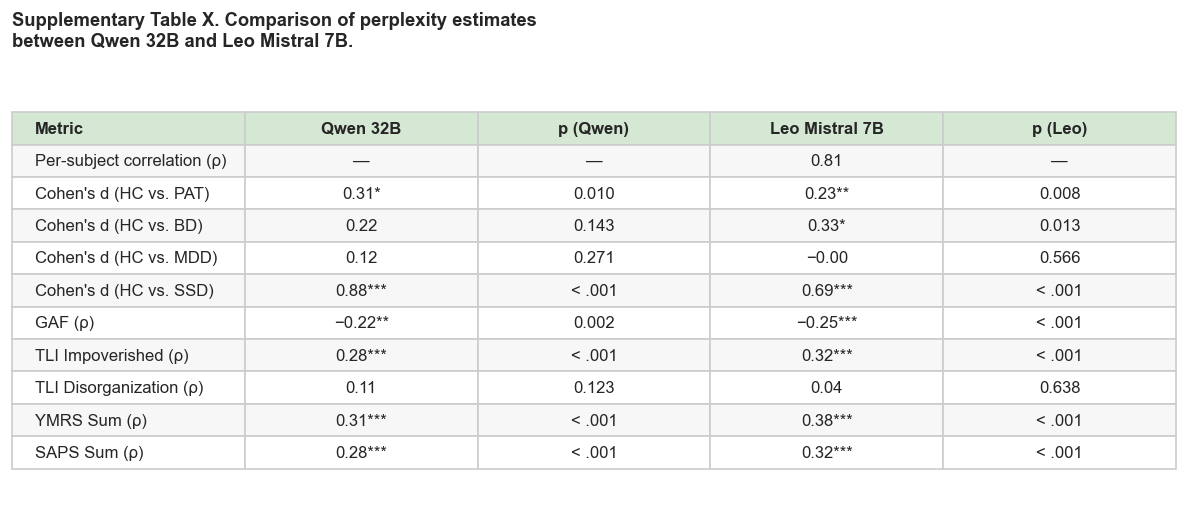

Supplementary table saved to /Users/lenze/code/HITKIP/mnm_ppl/figures/prompt_comparison


,Metric,Qwen 32B,p (Qwen),Leo Mistral 7B,p (Leo)
0,Per-subject correlation (ρ),—,—,0.81,—
1,Cohen's d (HC vs. PAT),0.31*,0.010,0.23**,0.008
2,Cohen's d (HC vs. BD),0.22,0.143,0.33*,0.013
3,Cohen's d (HC vs. MDD),0.12,0.271,−0.00,0.566
4,Cohen's d (HC vs. SSD),0.88***,< .001,0.69***,< .001
5,GAF (ρ),−0.22**,0.002,−0.25***,< .001
6,TLI Impoverished (ρ),0.28***,< .001,0.32***,< .001
7,TLI Disorganization (ρ),0.11,0.123,0.04,0.638
8,YMRS Sum (ρ),0.31***,< .001,0.38***,< .001
9,SAPS Sum (ρ),0.28***,< .001,0.32***,< .001


In [63]:

# ── Supplementary Table: Qwen 32B vs Leo Mistral 7B ───────────
from scipy.stats import spearmanr

def sig_stars(p):
    """Return significance stars for a p-value."""
    if pd.isna(p): return ""
    if p < 0.001: return "***"
    if p < 0.01: return "**"
    if p < 0.05: return "*"
    return ""

def fmt_val_sig(val, p, fmt=".2f"):
    """Format a value with significance stars appended."""
    if pd.isna(val): return "—"
    s = f"{val:{fmt}}"
    s = s.replace("-", "−")
    return f"{s}{sig_stars(p)}"

def fmt_p_val(p):
    """Format p-value for display."""
    if pd.isna(p): return "—"
    if p < 0.001: return "< .001"
    return f"{p:.3f}"

# Gather all values dynamically
rows_supp = []

# Per-subject correlation (ρ between models — single value, compute p)
rows_supp.append({"Metric": "Per-subject correlation (ρ)",
                   "Qwen 32B": "—", "p (Qwen)": "—",
                   "Leo Mistral 7B": f"{r_all:.2f}", "p (Leo)": "—"})

# Cohen's d — HC vs PAT (overall)
rows_supp.append({"Metric": "Cohen's d (HC vs. PAT)",
                   "Qwen 32B": f"{comp_qwen['Cohens d']:.2f}{sig_stars(comp_qwen['p(MW)'])}",
                   "p (Qwen)": fmt_p_val(comp_qwen['p(MW)']),
                   "Leo Mistral 7B": f"{comp_leo['Cohens d']:.2f}{sig_stars(comp_leo['p(MW)'])}",
                   "p (Leo)": fmt_p_val(comp_leo['p(MW)'])})

# Cohen's d — per diagnosis
for dx_label, dx_key in [("BD", "BD"), ("MDD", "MDD"), ("SSD", "SSD")]:
    d_q = d_pivot.loc[dx_key, "Qwen 32B"] if dx_key in d_pivot.index else np.nan
    d_l = d_pivot.loc[dx_key, "Leo Mistral 7B"] if dx_key in d_pivot.index else np.nan
    p_q = p_pivot_dx.loc[dx_key, "Qwen 32B"] if dx_key in p_pivot_dx.index else np.nan
    p_l = p_pivot_dx.loc[dx_key, "Leo Mistral 7B"] if dx_key in p_pivot_dx.index else np.nan
    rows_supp.append({"Metric": f"Cohen's d (HC vs. {dx_label})",
                       "Qwen 32B": fmt_val_sig(d_q, p_q),
                       "p (Qwen)": fmt_p_val(p_q),
                       "Leo Mistral 7B": fmt_val_sig(d_l, p_l),
                       "p (Leo)": fmt_p_val(p_l)})

# Clinical correlations
clin_map = {"GAF": "GAF (ρ)",
            "TLI_Impoverished": "TLI Impoverished (ρ)",
            "TLI_Disorganization": "TLI Disorganization (ρ)",
            "YMRS_Sum": "YMRS Sum (ρ)",
            "SAPS_Sum_ENIGMA": "SAPS Sum (ρ)"}

for cvar, cvar_label in clin_map.items():
    r_q, r_l, p_q, p_l = np.nan, np.nan, np.nan, np.nan
    # Try pivots first; if missing, compute directly
    if cvar in r_model_pivot.index:
        r_q = r_model_pivot.loc[cvar, "Qwen 32B"]
        r_l = r_model_pivot.loc[cvar, "Leo Mistral 7B"]
        p_q = p_model_pivot.loc[cvar, "Qwen 32B"]
        p_l = p_model_pivot.loc[cvar, "Leo Mistral 7B"]
    else:
        for df_pat, ppl_col, key in [(patients_qwen, QWEN_PPL, "q"),
                                      (patients_leo, LEO_PPL, "l")]:
            if cvar in df_pat.columns:
                sub = df_pat[[ppl_col, cvar]].dropna()
                if len(sub) >= 5:
                    rho, pval = spearmanr(sub[ppl_col], sub[cvar])
                    if key == "q": r_q, p_q = rho, pval
                    else: r_l, p_l = rho, pval
    rows_supp.append({"Metric": cvar_label,
                       "Qwen 32B": fmt_val_sig(r_q, p_q),
                       "p (Qwen)": fmt_p_val(p_q),
                       "Leo Mistral 7B": fmt_val_sig(r_l, p_l),
                       "p (Leo)": fmt_p_val(p_l)})

supp_df = pd.DataFrame(rows_supp)

# ── Render as publication-quality figure ───────────────────────
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axis("off")

title = "Supplementary Table X. Comparison of perplexity estimates\nbetween Qwen 32B and Leo Mistral 7B."
ax.set_title(title, fontsize=11, fontweight="bold", loc="left", pad=12)

col_labels = ["Metric", "Qwen 32B", "p (Qwen)", "Leo Mistral 7B", "p (Leo)"]
cell_text = supp_df[col_labels].values.tolist()

table = ax.table(cellText=cell_text, colLabels=col_labels,
                 cellLoc="center", loc="center", colColours=["#D5E8D4"] * 5)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.0, 1.5)

# Style: bold header, left-align metric column
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#CCCCCC")
    if row == 0:
        cell.set_text_props(fontweight="bold")
        cell.set_facecolor("#D5E8D4")
    else:
        cell.set_facecolor("#FFFFFF" if row % 2 == 0 else "#F7F7F7")
    if col == 0:
        cell.set_text_props(ha="left")
        cell._loc = "left"

fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "supplementary_table_model_comparison.png"),
            dpi=200, bbox_inches="tight", facecolor="white")
fig.savefig(os.path.join(FIGURE_DIR, "supplementary_table_model_comparison.pdf"),
            bbox_inches="tight", facecolor="white")
plt.show()

# Also save as CSV/Excel
supp_df.to_csv(os.path.join(FIGURE_DIR, "supplementary_table_model_comparison.csv"), index=False)
supp_df.to_excel(os.path.join(FIGURE_DIR, "supplementary_table_model_comparison.xlsx"), index=False)
print(f"Supplementary table saved to {FIGURE_DIR}")
display(supp_df)
